# 从零实现 Two-Layer Neural Network：Two Moons 二分类

你只用 NumPy 手写一个 `2 → 5 → 1` 的两层神经网络，完成 Forward Propagation、Binary Cross-Entropy、Backpropagation、Numerical Gradient Checking 和 Batch Gradient Descent。核心函数保留了完整签名、docstring 和 TODO 提示，函数体留给你实现。数据加载、公式、API 链接、自检和绘图代码已经提供。

## 使用方法

1. 在本目录运行 `uv sync`，然后在 VS Code / Jupyter 中选择 `.venv/bin/python` 作为 kernel。
2. 从上往下运行。遇到 `TODO` 函数时先实现它，再运行紧随其后的自检单元格。
3. 修改函数后要重新运行定义它的单元格。编辑器里的代码不会自动同步到 kernel。
4. 调用还没实现的函数会抛出 `NotImplementedError`。这是练习刚开始时的正常状态。
5. 实现时保持函数名、参数顺序和返回值约定不变。后面的自检和绘图代码依赖这些约定。
6. 全部完成后执行 Restart Kernel → Run All，确认结果不依赖旧变量。

**规则**：只用 NumPy 实现模型。scikit-learn 只用于生成数据和划分训练 / 测试集。不使用 PyTorch、TensorFlow、自动微分或现成的优化器。

## 路线

| Lab | 内容 | 你要实现的函数 | 已提供的观察图 |
| --- | --- | --- | --- |
| 1 | 数据准备 | `standardize_features` | 原始数据与标准化数据散点图 |
| 2 | 参数初始化 | `initialize_parameters` | He 初始化权重分布直方图 |
| 3 | Forward Propagation | `relu`, `relu_derivative`, `sigmoid`, `forward` | 激活函数及其导数曲线 |
| 4 | Loss 与 Backpropagation | `compute_loss`, `backward`, `gradient_check` | 梯度检查相对误差柱状图 |
| 5 | 训练循环 | `update_parameters`, `train` | Loss Curve（线性 / 对数坐标） |
| 6 | 评估与可视化 | `predict_proba`, `predict`, `accuracy` | 决策边界、隐藏神经元激活图、训练过程演化 |
| 7 | 实验 | 无（修改配置后观察） | 学习率对比、隐藏层宽度对比 |

一共 14 个函数。`plot_decision_boundary` 作为观察工具直接提供，不计入练习。想多练一步的话，可以在完成全部 Lab 后自己重写它。

## 1. Problem Definition

**任务**：给定二维坐标 $(x_1, x_2)$，预测这个点属于 Class 0 还是 Class 1。

| 项目 | 设定 |
| --- | --- |
| Input features | 2（$x_1$, $x_2$） |
| Output classes | 2（输出一个概率 $\hat y = P(y=1 \mid x)$） |
| Dataset size | 1,000 个样本，`noise=0.2`，`random_state=42` |
| Training / Test split | 80% / 20%，即 800 / 200，按类别分层（`stratify=y`） |

**为什么选 Two Moons？** 两类数据像两个交错的月牙。任何一条直线都没法把它们干净地分开，所以 Logistic Regression 这类线性模型会卡在大约 86% 的训练准确率。隐藏层加上 ReLU 这样的非线性激活函数后，网络可以学出弯曲的决策边界。Lab 6 会把两种决策边界画在一起比较。

数据只有两维，所以每一步都能画出来：数据分布、每个隐藏神经元"看到"的区域、训练过程中边界怎样一点点弯过去。

## 2. 环境与 API 速查

下表只列出实现所需的**部分参数**，不是 API 的全部参数。

### 2.1 数据（已提供，只需读懂）

| API（官方文档） | 关键参数 / 返回值 | 用在哪里 |
| --- | --- | --- |
| [`sklearn.datasets.make_moons`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_moons.html) | `n_samples`, `noise`, `random_state` → `X (n, 2)`, `y (n,)` | 生成数据 |
| [`sklearn.model_selection.train_test_split`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) | `test_size`, `random_state`, `stratify` → `X_train, X_test, y_train, y_test` | 划分数据 |
| [`ndarray.reshape(-1, 1)`](https://numpy.org/doc/stable/reference/generated/numpy.ndarray.reshape.html) | `-1` 表示自动推断这一维 → `(m,)` 变成 `(m, 1)` | 把标签变成列向量 |
| [`np.unique(a, return_counts=True)`](https://numpy.org/doc/stable/reference/generated/numpy.unique.html) | 返回去重后的值和每个值出现的次数 | 检查标签只有 0 和 1 |

### 2.2 创建数组与随机数

| API（官方文档） | 关键参数 / 返回值 | 用在哪个函数 |
| --- | --- | --- |
| [`np.random.seed(seed)`](https://numpy.org/doc/stable/reference/random/generated/numpy.random.seed.html) | 固定全局随机数状态，让结果可复现 | `initialize_parameters` |
| [`np.random.randn(d0, d1)`](https://numpy.org/doc/stable/reference/random/generated/numpy.random.randn.html) | 从标准正态分布 $\mathcal N(0,1)$ 采样，返回形状 `(d0, d1)` | `initialize_parameters` |
| [`np.sqrt(x)`](https://numpy.org/doc/stable/reference/generated/numpy.sqrt.html) | 平方根 | He 初始化的缩放系数 |
| [`np.zeros(shape)`](https://numpy.org/doc/stable/reference/generated/numpy.zeros.html) | `shape` 是元组，例如 `(1, 5)` | bias 初始化 |
| [`np.zeros_like(a)`](https://numpy.org/doc/stable/reference/generated/numpy.zeros_like.html) | 返回与 `a` 同形状、同 dtype 的全零数组 | `gradient_check` 存放数值梯度 |

### 2.3 逐元素运算

| API（官方文档） | 关键参数 / 返回值 | 用在哪个函数 |
| --- | --- | --- |
| [`np.maximum(a, b)`](https://numpy.org/doc/stable/reference/generated/numpy.maximum.html) | 逐元素取较大值，支持广播：`np.maximum(0, Z)` | `relu` |
| 比较运算 `Z > 0`、`P >= t` | 返回布尔数组 | `relu_derivative`（`>`）、`predict`（`>=`） |
| [`ndarray.astype(dtype)`](https://numpy.org/doc/stable/reference/generated/numpy.ndarray.astype.html) | 转换类型，例如布尔 → `float` 或 `int` | `relu_derivative`, `predict` |
| [`np.exp(x)`](https://numpy.org/doc/stable/reference/generated/numpy.exp.html) | 逐元素 $e^x$ | `sigmoid` |
| [`np.log(x)`](https://numpy.org/doc/stable/reference/generated/numpy.log.html) | 自然对数 $\ln x$（不是 `log10`） | `compute_loss` |
| [`np.clip(a, a_min, a_max)`](https://numpy.org/doc/stable/reference/generated/numpy.clip.html) | 把值限制在区间内，返回新数组 | `compute_loss` 避免 `log(0)` |

### 2.4 矩阵运算与聚合

| API（官方文档） | 关键参数 / 返回值 | 用在哪个函数 |
| --- | --- | --- |
| [`A @ B`（`np.matmul`）](https://numpy.org/doc/stable/reference/generated/numpy.matmul.html) | 矩阵乘法：`(m, n) @ (n, k)` → `(m, k)` | `forward`, `backward` |
| [`A.T`](https://numpy.org/doc/stable/reference/generated/numpy.ndarray.T.html) | 转置：`(m, n)` → `(n, m)` | `backward` |
| [`np.sum(a, axis=0, keepdims=True)`](https://numpy.org/doc/stable/reference/generated/numpy.sum.html) | `axis=0` 沿样本方向求和；`keepdims=True` 保留二维形状，例如 `(m, 5)` → `(1, 5)` | `backward` 计算 `db1`, `db2` |
| [`np.mean(a, axis=0, keepdims=True)`](https://numpy.org/doc/stable/reference/generated/numpy.mean.html) | 平均值；不传 `axis` 时对全部元素求平均 | `standardize_features`, `compute_loss`, `accuracy` |
| [`np.std(a, axis=0, keepdims=True)`](https://numpy.org/doc/stable/reference/generated/numpy.std.html) | 标准差，默认 `ddof=0`（总体标准差） | `standardize_features` |
| [`np.linalg.norm(x)`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.norm.html) | 默认计算 L2 范数 $\lVert x\rVert_2$，对矩阵展平后计算 | `gradient_check` 相对误差 |
| [Broadcasting](https://numpy.org/doc/stable/user/basics.broadcasting.html) | `(m, 5) + (1, 5)` 会把 bias 加到每一行 | `forward` |

### 2.5 复制、遍历与训练循环

| API（官方文档） | 关键参数 / 返回值 | 用在哪个函数 |
| --- | --- | --- |
| [`ndarray.copy()`](https://numpy.org/doc/stable/reference/generated/numpy.ndarray.copy.html) | 返回独立副本，修改副本不会影响原数组 | `gradient_check` |
| [dict comprehension](https://docs.python.org/3.13/tutorial/datastructures.html#dictionaries) | `{k: v.copy() for k, v in d.items()}` 复制整个参数字典 | `gradient_check`, `update_parameters` |
| [`np.ndindex(shape)`](https://numpy.org/doc/stable/reference/generated/numpy.ndindex.html) | 传入一个形状元组（例如 `(2, 5)`），依次给出其中每个位置的索引元组 `(0, 0), (0, 1), ...` | `gradient_check` 逐个扰动参数 |
| [`ndarray.shape`](https://numpy.org/doc/stable/reference/generated/numpy.ndarray.shape.html) | 各维大小组成的元组：`X.shape[0]` 是样本数 $m$，`X.shape[1]` 是特征数 | `backward`, `train` |
| [`float(x)`](https://docs.python.org/3.13/library/functions.html#float) | 把 NumPy 标量转换成 Python `float` | `compute_loss`, `gradient_check`, `accuracy` |
| [`range(n)`](https://docs.python.org/3.13/library/stdtypes.html#range) | 产生 `0, 1, ..., n-1` | `train` |
| [`list.append(x)`](https://docs.python.org/3.13/tutorial/datastructures.html#more-on-lists) | 在列表末尾追加元素 | `train` 记录 loss |
| `epoch % log_every == 0` | 取余为 0 时表示到了记录点 | `train` |

### 2.6 绘图（已提供，读懂即可）

| API（官方文档） | 作用 |
| --- | --- |
| [`np.meshgrid`](https://numpy.org/doc/stable/reference/generated/numpy.meshgrid.html), [`np.linspace`](https://numpy.org/doc/stable/reference/generated/numpy.linspace.html) | 在平面上生成网格点 |
| [`np.c_`](https://numpy.org/doc/stable/reference/generated/numpy.c_.html), [`ndarray.ravel`](https://numpy.org/doc/stable/reference/generated/numpy.ravel.html) | 把网格展平成 `(k, 2)` 的样本矩阵 |
| [`plt.subplots`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html) | 创建图和子图 |
| [`Axes.contourf`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.contourf.html), [`Axes.contour`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.contour.html) | 画概率填充图和 $\hat y = 0.5$ 等高线（决策边界） |
| [`Axes.scatter`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.scatter.html), [`Axes.plot`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.plot.html) | 散点图、折线图 |
| [`Axes.set_yscale("log")`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.set_yscale.html) | 对数纵轴，看清 loss 的后期变化 |

### 2.7 自检

| API（官方文档） | 作用 |
| --- | --- |
| [`np.testing.assert_allclose(actual, desired, atol=...)`](https://numpy.org/doc/stable/reference/generated/numpy.testing.assert_allclose.html) | 在容差内比较数组，不相等时显示差异 |
| [`assert`](https://docs.python.org/3.13/reference/simple_stmts.html#the-assert-statement) | 条件为假时抛出 `AssertionError` |
| [`raise ValueError(msg)`](https://docs.python.org/3.13/tutorial/errors.html#raising-exceptions) | 主动抛出异常，`msg` 写明出错原因；`accuracy` 在两个数组形状不同时用它 |

In [2]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)

# 统一的绘图样式：两个类别用蓝 / 橙区分，并且用不同形状的点作为第二重编码。
CLASS_COLORS = {0: "#2a78d6", 1: "#eb6834"}
CLASS_MARKERS = {0: "o", 1: "^"}
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]
# 概率背景：0 → 蓝，0.5 → 中性灰，1 → 橙。
PROBA_CMAP = LinearSegmentedColormap.from_list(
    "proba", ["#2a78d6", "#9cc3f0", "#f0efec", "#f6b89c", "#eb6834"]
)
# 隐藏层激活强度：单一色相，从浅到深。
ACTIVATION_CMAP = LinearSegmentedColormap.from_list("activation", ["#fcfcfb", "#2a78d6", "#0d3a73"])

# 中文字体回退：依次尝试 macOS / Windows / Linux 上常见的中文字体，让图中的中文标题正常显示。
plt.rcParams["font.sans-serif"] = [
    "PingFang SC", "Heiti SC", "Arial Unicode MS", "Microsoft YaHei", "SimHei",
    "Noto Sans CJK SC", "WenQuanYi Micro Hei", "DejaVu Sans",
]
plt.rcParams["axes.unicode_minus"] = False  # 部分中文字体没有 Unicode 负号

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 11,
})

NumPy: 2.5.4
Matplotlib: 3.11.2


## 3. 核心参数配置

下面是第一版固定使用的配置。它们只是实验起点，并不是最优配置。第 7 节会让你自己改动它们并观察结果。

| Hyperparameter | 代码常量 | 初始值 | 说明 |
| --- | --- | --- | --- |
| Input features | `N_INPUT` | 2 | $x_1, x_2$ |
| Hidden units | `N_HIDDEN` | 5 | 隐藏层宽度 |
| Output units | `N_OUTPUT` | 1 | 一个概率 |
| Hidden activation | 无 | ReLU | 第 7 节的拓展题可以换成 Tanh |
| Output activation | 无 | Sigmoid | 二分类输出 |
| Loss | 无 | Binary Cross-Entropy | 二分类任务 |
| Learning rate $\alpha$ | `LEARNING_RATE` | 0.05 | 每一步沿负梯度走多远 |
| Epochs | `EPOCHS` | 5,000 | Batch GD 中每个 epoch 只更新一次参数 |
| Loss 记录间隔 | `LOG_EVERY` | 100 | 每 100 个 epoch 记录一次 loss |
| Optimizer | 无 | Batch Gradient Descent | 每次更新都用全部 800 个训练样本 |
| Weight initialization | 无 | He Initialization | 适合 ReLU |
| Bias initialization | 无 | Zeros | 标准做法 |
| Regularization | 无 | None | 第一版不使用 |
| Random seed | `SEED` | 42 | 保证实验可复现 |
| Gradient check $\varepsilon$ | `GRAD_CHECK_EPSILON` | $10^{-5}$ | 中心差分的步长 |

模型共有 $2\times5 + 5 + 5\times1 + 1 = 21$ 个可训练参数。

In [3]:
# 数据设定
N_SAMPLES = 1000
NOISE = 0.2
TEST_SIZE = 0.2
SEED = 42

# 网络结构
N_INPUT = 2
N_HIDDEN = 5
N_OUTPUT = 1

# 优化设定
LEARNING_RATE = 0.05
EPOCHS = 5000
LOG_EVERY = 100

# 梯度检查
GRAD_CHECK_EPSILON = 1e-5

n_params = N_INPUT * N_HIDDEN + N_HIDDEN + N_HIDDEN * N_OUTPUT + N_OUTPUT
print("可训练参数数量：", n_params)
assert n_params == 21

可训练参数数量： 21


## 4. 公式总表

实现时随时回来查这一节。每个 Lab 开头还会重复它用到的那几条公式。

### 4.1 符号与形状

$m$ 是样本数（训练时 $m=800$）。**每一行是一个样本**，所以输入写成 $XW$，而不是 $WX$。

| 数学符号 | 代码变量 | Shape | 含义 |
| --- | --- | --- | --- |
| $X$ | `X` | $(m, 2)$ | 输入（已标准化） |
| $Y$ | `Y` | $(m, 1)$ | 真实标签，0 或 1 |
| $W^{[1]}$ | `parameters["W1"]` | $(2, 5)$ | Hidden weights |
| $b^{[1]}$ | `parameters["b1"]` | $(1, 5)$ | Hidden bias |
| $Z^{[1]}$ | `cache["Z1"]` | $(m, 5)$ | 隐藏层线性输出 |
| $A^{[1]}$ | `cache["A1"]` | $(m, 5)$ | 隐藏层激活值 |
| $W^{[2]}$ | `parameters["W2"]` | $(5, 1)$ | Output weights |
| $b^{[2]}$ | `parameters["b2"]` | $(1, 1)$ | Output bias |
| $Z^{[2]}$ | `cache["Z2"]` | $(m, 1)$ | 输出层线性输出（logit） |
| $\hat Y$ | `cache["Y_hat"]` | $(m, 1)$ | 属于 Class 1 的概率 |
| $dW^{[l]}, db^{[l]}$ | `grads["dW1"]` 等 | 与对应参数相同 | 平均 loss 对参数的梯度 |

### 4.2 特征标准化（只用训练集的统计量）

$$
\mu_j=\frac{1}{m_{\text{train}}}\sum_{i=1}^{m_{\text{train}}}x_{ij},\qquad
\sigma_j=\sqrt{\frac{1}{m_{\text{train}}}\sum_{i=1}^{m_{\text{train}}}\left(x_{ij}-\mu_j\right)^2},\qquad
\tilde x_{ij}=\frac{x_{ij}-\mu_j}{\sigma_j}
$$

测试集用**训练集**的 $\mu$ 和 $\sigma$ 来变换。

### 4.3 He Initialization

$$
W^{[1]}\sim\mathcal N\!\left(0,\frac{2}{n_{\text{in}}}\right)\ \text{with}\ n_{\text{in}}=2,\qquad
W^{[2]}\sim\mathcal N\!\left(0,\frac{2}{n_{\text{in}}}\right)\ \text{with}\ n_{\text{in}}=5,\qquad
b^{[1]}=0,\ b^{[2]}=0
$$

代码：`np.random.randn(n_in, n_out) * np.sqrt(2 / n_in)`。注意 $\mathcal N(0, \sigma^2)$ 的第二个参数是**方差**，所以要乘的是标准差 $\sqrt{2/n_{\text{in}}}$。

### 4.4 激活函数及其导数

$$
\operatorname{ReLU}(z)=\max(0,z),\qquad
\operatorname{ReLU}'(z)=\begin{cases}1,& z>0\\0,& z\le 0\end{cases}
$$

$$
\sigma(z)=\frac{1}{1+e^{-z}},\qquad \sigma'(z)=\sigma(z)\bigl(1-\sigma(z)\bigr)
$$

ReLU 在 $z=0$ 处没有导数。本练习约定这一点的导数取 0。

### 4.5 Forward Propagation

$$
Z^{[1]}=XW^{[1]}+b^{[1]},\qquad A^{[1]}=\operatorname{ReLU}(Z^{[1]})
$$

$$
Z^{[2]}=A^{[1]}W^{[2]}+b^{[2]},\qquad \hat Y=\sigma(Z^{[2]})
$$

$b^{[1]}$ 的形状是 $(1,5)$，通过 broadcasting 加到 $(m,5)$ 的每一行上。

### 4.6 Binary Cross-Entropy

$$
J=-\frac1m\sum_{i=1}^{m}\Bigl[y_i\log(\hat y_i)+(1-y_i)\log(1-\hat y_i)\Bigr]
$$

计算前先把概率限制在 $[10^{-12},\,1-10^{-12}]$，避免 $\log 0$。

### 4.7 Backpropagation

$$
\begin{aligned}
dZ^{[2]} &= \hat Y - Y && (m,1)\\
dW^{[2]} &= \tfrac{1}{m}\,{A^{[1]}}^{\top} dZ^{[2]} && (5,m)(m,1)\to(5,1)\\
db^{[2]} &= \tfrac{1}{m}\textstyle\sum_{i=1}^{m} dZ^{[2]}_{i,:} && (1,1)\\
dA^{[1]} &= dZ^{[2]}\,{W^{[2]}}^{\top} && (m,1)(1,5)\to(m,5)\\
dZ^{[1]} &= dA^{[1]} \odot \operatorname{ReLU}'(Z^{[1]}) && (m,5)\\
dW^{[1]} &= \tfrac{1}{m}\,X^{\top} dZ^{[1]} && (2,m)(m,5)\to(2,5)\\
db^{[1]} &= \tfrac{1}{m}\textstyle\sum_{i=1}^{m} dZ^{[1]}_{i,:} && (1,5)
\end{aligned}
$$

- $\odot$ 是逐元素乘法，代码里用 `*`；矩阵乘法用 `@`。
- $\sum_i$ 是沿样本方向（`axis=0`）求和，结果保持二维形状。
- $dZ^{[2]}$、$dA^{[1]}$、$dZ^{[1]}$ 的第 $i$ 行是**第 $i$ 个样本自己的 loss** $\ell_i$ 的导数，都没有除以 $m$。$\tfrac1m$ 只在算 $dW$、$db$ 时乘一次，把 $m$ 个样本的梯度变成平均值，对应 $J$ 里的 $\tfrac1m$。也有教材在 $dZ^{[2]}$ 处就除以 $m$，那样后面就不能再除。两种写法得到的 $dW$、$db$ 完全一样，关键是 $\tfrac1m$ 只出现一次。

<details>
<summary><b>推导过程（点击展开）</b></summary>

先看一个样本。令 $\ell=-\bigl[y\log\hat y+(1-y)\log(1-\hat y)\bigr]$，$\hat y=\sigma(z^{[2]})$。

1. Loss 对概率求导：$\dfrac{\partial \ell}{\partial \hat y}=-\dfrac{y}{\hat y}+\dfrac{1-y}{1-\hat y}=\dfrac{\hat y-y}{\hat y(1-\hat y)}$。
2. Sigmoid 对 logit 求导：$\dfrac{\partial \hat y}{\partial z^{[2]}}=\hat y(1-\hat y)$。
3. 两者相乘后分母约掉：$\dfrac{\partial \ell}{\partial z^{[2]}}=\hat y-y$。这就是 $dZ^{[2]}$ 中的一行。
4. 因为 $z^{[2]}=\sum_j a^{[1]}_j W^{[2]}_j+b^{[2]}$，所以 $\dfrac{\partial z^{[2]}}{\partial W^{[2]}_j}=a^{[1]}_j$，$\dfrac{\partial z^{[2]}}{\partial b^{[2]}}=1$，$\dfrac{\partial z^{[2]}}{\partial a^{[1]}_j}=W^{[2]}_j$。
5. 因为 $a^{[1]}_j=\operatorname{ReLU}(z^{[1]}_j)$，所以 $\dfrac{\partial a^{[1]}_j}{\partial z^{[1]}_j}=\operatorname{ReLU}'(z^{[1]}_j)$。
6. 因为 $z^{[1]}_j=\sum_k x_k W^{[1]}_{kj}+b^{[1]}_j$，所以 $\dfrac{\partial z^{[1]}_j}{\partial W^{[1]}_{kj}}=x_k$，$\dfrac{\partial z^{[1]}_j}{\partial b^{[1]}_j}=1$。
7. 沿链式法则把这些因子连乘，再对 $m$ 个样本取平均，就得到上面的矩阵形式。$X^{\top}dZ^{[1]}$ 里的矩阵乘法已经完成了"对样本求和"这一步，所以只需要再除以 $m$。

**形状检验法**：一个梯度的形状必须和它对应的参数完全相同。把转置放错位置时，形状通常对不上。

</details>

### 4.8 Gradient Descent 参数更新

$$
W^{[l]}\leftarrow W^{[l]}-\alpha\,dW^{[l]},\qquad b^{[l]}\leftarrow b^{[l]}-\alpha\,db^{[l]},\qquad l\in\{1,2\}
$$

### 4.9 Numerical Gradient Checking

对每个参数元素 $\theta_k$，分别向两侧扰动 $\varepsilon$，保持其他参数不变：

$$
g^{\text{num}}_k=\frac{J(\theta_k+\varepsilon)-J(\theta_k-\varepsilon)}{2\varepsilon}
$$

然后把数值梯度 $g^{\text{num}}$ 和 `backward` 算出的解析梯度 $g^{\text{ana}}$ 比较：

$$
\text{relative error}=\frac{\lVert g^{\text{num}}-g^{\text{ana}}\rVert_2}{\lVert g^{\text{num}}\rVert_2+\lVert g^{\text{ana}}\rVert_2+10^{-12}}
$$

| 相对误差 | 解读 |
| --- | --- |
| $< 10^{-7}$ | 梯度正确 |
| $10^{-7}$ 到 $10^{-4}$ | 需要检查；也可能是某个 $Z^{[1]}$ 恰好非常接近 ReLU 的折点 0：这时 $\pm\varepsilon$ 的扰动跨过了折点，中心差分就不再准确 |
| $> 10^{-4}$ | 几乎可以肯定 `backward` 有 bug |

### 4.10 预测与准确率

$$
\hat y^{\text{class}}_i=\begin{cases}1,&\hat y_i\ge 0.5\\0,&\hat y_i<0.5\end{cases},\qquad
\text{Accuracy}=\frac1m\sum_{i=1}^{m}\mathbb 1\!\left[\hat y^{\text{class}}_i=y_i\right]
$$

### 4.11 决策边界

决策边界是满足 $\hat y(x)=0.5$ 的点集，等价于 $z^{[2]}(x)=0$：

$$
z^{[2]}(x)=\sum_{j=1}^{5}W^{[2]}_j\,\operatorname{ReLU}\!\bigl(x\,W^{[1]}_{:,j}+b^{[1]}_j\bigr)+b^{[2]}=0
$$

- **Logistic Regression**：$xW+b=0$，永远是一条直线。
- **本网络**：每个隐藏神经元对应一条直线 $x\,W^{[1]}_{:,j}+b^{[1]}_j=0$。直线一侧这个神经元输出 0，另一侧输出随 $x$ 线性增长。这些直线把平面切成若干块，每一块里 $z^{[2]}(x)$ 都是线性函数，所以决策边界在每一块里是一段直线，只在穿过这些直线时转弯，整体是一条折线。隐藏神经元越多，可以转弯的地方就越多。Lab 6 的隐藏神经元激活图会用虚线画出每个神经元的这条直线。

## Lab 1：Dataset Preparation

下面的数据加载和划分代码使用第 1 节的设定，不要改随机种子。

`make_moons` 返回的 `y` 形状是 `(m,)`。我们会把它变成 `(m, 1)` 的列向量，让它和 $\hat Y$ 的形状一致。这一步不能省：`(m, 1) - (m,)` 不会报错，而是广播成 `(m, m)` 的矩阵，之后的 loss 和梯度会悄悄算错。

**你要实现**：`standardize_features(X_train, X_test)`

$$
\mu=\operatorname{mean}(X_{\text{train}}),\quad \sigma=\operatorname{std}(X_{\text{train}}),\quad
\tilde X_{\text{train}}=\frac{X_{\text{train}}-\mu}{\sigma},\quad \tilde X_{\text{test}}=\frac{X_{\text{test}}-\mu}{\sigma}
$$

- $\mu$、$\sigma$ 按列计算，形状是 `(1, 2)`。
- **只用训练集**算 $\mu$ 和 $\sigma$。如果把测试集也算进去，测试集的信息就泄漏到了训练过程中。
- API：`np.mean(..., axis=0, keepdims=True)`、`np.std(..., axis=0, keepdims=True)`。

In [4]:
# 已提供：数据生成和划分，使用第 1 节的设定。
X, y = make_moons(n_samples=N_SAMPLES, noise=NOISE, random_state=SEED)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=y,
)

# 把标签从 (m,) 变成 (m, 1) 列向量，和 Y_hat 的形状保持一致。
y_train = y_train.reshape(-1, 1)
y_test = y_test.reshape(-1, 1)

print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("X_test: ", X_test.shape, " y_test: ", y_test.shape)

X_train: (800, 2)  y_train: (800, 1)
X_test:  (200, 2)  y_test:  (200, 1)


In [5]:
def standardize_features(
    X_train: np.ndarray,
    X_test: np.ndarray,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """只用训练集的统计量标准化训练集和测试集。

    Parameters
    ----------
    X_train : ndarray, shape (m_train, n_x)
        原始训练特征。
    X_test : ndarray, shape (m_test, n_x)
        原始测试特征。

    Returns
    -------
    X_train_std : ndarray, shape (m_train, n_x)
    X_test_std : ndarray, shape (m_test, n_x)
    mean : ndarray, shape (1, n_x)
        训练集每列的均值。
    std : ndarray, shape (1, n_x)
        训练集每列的总体标准差（ddof=0）。

    Notes
    -----
    不修改输入数组；不用 X_test 计算 mean 或 std。
    """
    # TODO: 用 X_train 按列计算 mean 和 std，保留 (1, n_x) 形状。
    mean = np.mean(X_train, axis=0, keepdims=True)
    std = np.std(X_train, axis = 0, keepdims = True)
    X_train_std = (X_train - mean) / std
    X_test_std = (X_test - mean) / std

    # TODO: 用同一组 mean、std 变换 X_train 和 X_test，按约定顺序返回四个数组。
    return (X_train_std, X_test_std, mean, std)
    # raise NotImplementedError("TODO Lab 1: implement standardize_features")

In [6]:
# Lab 1 自检：用一个可以心算的小例子。
A_train = np.array([[1.0, 10.0], [3.0, 14.0], [5.0, 18.0]])
A_test = np.array([[7.0, 22.0]])
A_train_before, A_test_before = A_train.copy(), A_test.copy()

A_train_std, A_test_std, mean_a, std_a = standardize_features(A_train, A_test)
assert mean_a.shape == (1, 2) and std_a.shape == (1, 2), "mean / std 应该是 (1, 2)"
np.testing.assert_allclose(mean_a, [[3.0, 14.0]])
np.testing.assert_allclose(std_a, [[np.sqrt(8 / 3), np.sqrt(32 / 3)]])
np.testing.assert_allclose(A_train_std.mean(axis=0), [0.0, 0.0], atol=1e-12)
np.testing.assert_allclose(A_train_std.std(axis=0), [1.0, 1.0], atol=1e-12)
# 测试样本用训练集的统计量变换，所以它不会被拉回均值 0。
np.testing.assert_allclose(A_test_std, (A_test - mean_a) / std_a)
assert np.all(A_test_std > 0)
np.testing.assert_array_equal(A_train, A_train_before)
np.testing.assert_array_equal(A_test, A_test_before)
print("Lab 1 standardize_features 自检通过。")

Lab 1 standardize_features 自检通过。


In [7]:
# 对真实数据做标准化，并检查预期的形状。
X_train_std, X_test_std, feature_mean, feature_std = standardize_features(X_train, X_test)

assert X_train_std.shape == (800, 2)
assert X_test_std.shape == (200, 2)
assert y_train.shape == (800, 1) and y_test.shape == (200, 1)
assert set(np.unique(y)) == {0, 1}
np.testing.assert_allclose(X_train_std.mean(axis=0), [0.0, 0.0], atol=1e-10)
np.testing.assert_allclose(X_train_std.std(axis=0), [1.0, 1.0], atol=1e-10)

labels, counts = np.unique(y_train, return_counts=True)
print("训练集均值：", feature_mean.ravel())
print("训练集标准差：", feature_std.ravel())
print("训练集各类别数量：", dict(zip(labels.tolist(), counts.tolist())))
print("数据检查通过。")

训练集均值： [0.49753987 0.24518611]
训练集标准差： [0.89106881 0.52644137]
训练集各类别数量： {0: 400, 1: 400}
数据检查通过。


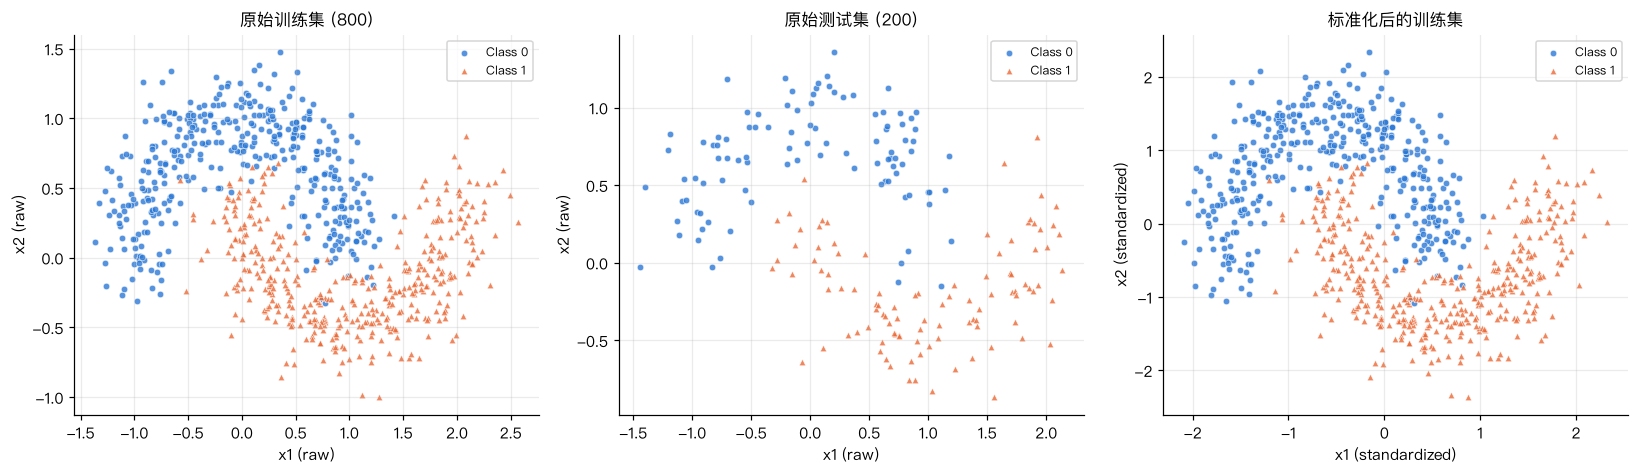

In [8]:
# 观察图 1：原始数据（训练 / 测试）和标准化后的训练数据。
def scatter_classes(ax, X_points, Y_points, size=18, alpha=0.8, label_suffix=""):
    """按类别画散点：颜色和形状同时区分两类。"""
    Y_flat = Y_points.ravel()
    for cls in (0, 1):
        mask = Y_flat == cls
        ax.scatter(
            X_points[mask, 0], X_points[mask, 1],
            s=size, alpha=alpha, c=CLASS_COLORS[cls], marker=CLASS_MARKERS[cls],
            edgecolors="white", linewidths=0.4, label=f"Class {cls}{label_suffix}",
        )


fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
scatter_classes(axes[0], X_train, y_train)
axes[0].set_title("原始训练集 (800)")
scatter_classes(axes[1], X_test, y_test)
axes[1].set_title("原始测试集 (200)")
scatter_classes(axes[2], X_train_std, y_train)
axes[2].set_title("标准化后的训练集")
for ax, unit in zip(axes, ["raw", "raw", "standardized"]):
    ax.set_xlabel(f"x1 ({unit})")
    ax.set_ylabel(f"x2 ({unit})")
    ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

## Lab 2：Parameter Initialization

**你要实现**：`initialize_parameters(n_input, n_hidden, n_output, seed=42)`

$$
W^{[1]}=\texttt{randn}(n_{\text{input}},n_{\text{hidden}})\cdot\sqrt{\tfrac{2}{n_{\text{input}}}},\qquad
W^{[2]}=\texttt{randn}(n_{\text{hidden}},n_{\text{output}})\cdot\sqrt{\tfrac{2}{n_{\text{hidden}}}},\qquad
b^{[1]}=\mathbf 0_{(1,n_{\text{hidden}})},\ b^{[2]}=\mathbf 0_{(1,n_{\text{output}})}
$$

约定：

1. `seed` 不是 `None` 时，先调用 `np.random.seed(seed)`，然后**先生成 `W1`、再生成 `W2`**。顺序固定，结果才能复现。
2. 返回一个字典，键名是 `"W1"`、`"b1"`、`"W2"`、`"b2"`。
3. 每层的 $n_{\text{in}}$ 是这一层的输入宽度：第一层是 `n_input`，第二层是 `n_hidden`。

**为什么权重不能全设成 0？** 如果所有隐藏神经元的初始权重都一样，它们算出的输出和梯度也一样，每次更新后仍然一样。5 个神经元就退化成了 1 个。随机初始化打破了这种对称。bias 可以从 0 开始，因为权重已经不同了。

**为什么乘 $\sqrt{2/n_{\text{in}}}$？** 每个神经元把 $n_{\text{in}}$ 个加权输入加起来，所以 $Z$ 的方差会随 $n_{\text{in}}$ 成比例增大。权重方差取 $1/n_{\text{in}}$ 正好抵消这种增长，输出的方差大致和输入相同。ReLU 又把大约一半的值变成 0，信号强度减半，所以 He 初始化把权重方差加倍成 $2/n_{\text{in}}$，补回丢掉的那一半。这样信号的方差一层层传下去大致不变，不会越来越接近 0，也不会越来越大。

In [29]:
def initialize_parameters(
    n_input: int,
    n_hidden: int,
    n_output: int,
    seed: int | None = 42,
) -> dict[str, np.ndarray]:
    """用 He Initialization 初始化权重，bias 初始化为 0。

    Parameters
    ----------
    n_input : int
        输入特征数，本题为 2。
    n_hidden : int
        隐藏层神经元数，本题为 5。
    n_output : int
        输出神经元数，本题为 1。
    seed : int or None
        不是 None 时先调用 np.random.seed(seed)。

    Returns
    -------
    parameters : dict
        "W1": (n_input, n_hidden)   标准差 sqrt(2 / n_input)
        "b1": (1, n_hidden)         全 0
        "W2": (n_hidden, n_output)  标准差 sqrt(2 / n_hidden)
        "b2": (1, n_output)         全 0

    Notes
    -----
    必须先生成 W1，再生成 W2。
    """
    # TODO: 设置随机种子（seed 不是 None 时）。
    if seed is not None:
        seed = np.random.seed(seed)
    # TODO: 用 np.random.randn 乘以对应的 He 缩放系数，依次生成 W1、W2。
    W1 = np.random.randn(n_input, n_hidden) * np.sqrt(2 / n_input)
    b1 = np.zeros((1, n_hidden))
    W2 = np.random.randn(n_hidden, n_output) * np.sqrt(2 / n_hidden)
    b2 = np.zeros((1, n_output))
    # TODO: 用 np.zeros 生成二维的 b1、b2，返回参数字典。

    return {"W1": W1, "b1": b1, "W2": W2, "b2": b2}
    # raise NotImplementedError("TODO Lab 2: implement initialize_parameters")

In [10]:
# Lab 2 自检
params_check = initialize_parameters(N_INPUT, N_HIDDEN, N_OUTPUT, seed=SEED)
assert set(params_check) == {"W1", "b1", "W2", "b2"}, "键名应该是 W1, b1, W2, b2"
expected_shapes = {"W1": (2, 5), "b1": (1, 5), "W2": (5, 1), "b2": (1, 1)}
for name, shape in expected_shapes.items():
    assert params_check[name].shape == shape, f"{name}: {params_check[name].shape} != {shape}"
np.testing.assert_array_equal(params_check["b1"], 0.0)
np.testing.assert_array_equal(params_check["b2"], 0.0)
assert sum(p.size for p in params_check.values()) == 21

# 同一个 seed 结果相同，不同 seed 结果不同。
again = initialize_parameters(N_INPUT, N_HIDDEN, N_OUTPUT, seed=SEED)
np.testing.assert_array_equal(params_check["W1"], again["W1"])
other = initialize_parameters(N_INPUT, N_HIDDEN, N_OUTPUT, seed=SEED + 1)
assert not np.allclose(params_check["W1"], other["W1"])

# 生成顺序：W1 必须是这个 seed 下的第一批随机数。
np.random.seed(SEED)
np.testing.assert_allclose(params_check["W1"], np.random.randn(2, 5) * np.sqrt(2 / 2))

# 用一个很宽的层检查缩放：样本标准差应该接近 sqrt(2 / n_in)。
wide = initialize_parameters(400, 300, 200, seed=0)
np.testing.assert_allclose(wide["W1"].std(), np.sqrt(2 / 400), rtol=0.05)
np.testing.assert_allclose(wide["W2"].std(), np.sqrt(2 / 300), rtol=0.05)
print("Lab 2 initialize_parameters 自检通过。")
print("W1 =\n", params_check["W1"])
print("W2 =\n", params_check["W2"])

Lab 2 initialize_parameters 自检通过。
W1 =
 [[ 0.49671415 -0.1382643   0.64768854  1.52302986 -0.23415337]
 [-0.23413696  1.57921282  0.76743473 -0.46947439  0.54256004]]
W2 =
 [[-0.29309108]
 [-0.29455336]
 [ 0.15303038]
 [-1.21006468]
 [-1.09093383]]


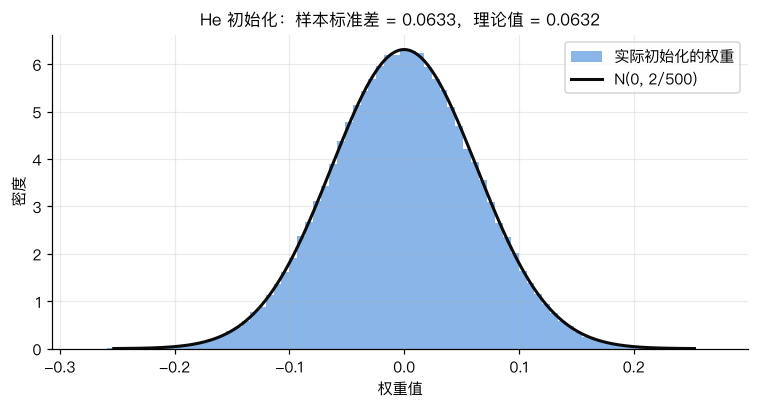

In [11]:
# 观察图 2：He 初始化的权重分布和理论正态分布 N(0, 2/n_in) 是否一致。
n_in_demo = 500
W_demo = initialize_parameters(n_in_demo, 500, 1, seed=0)["W1"].ravel()
sigma_demo = np.sqrt(2 / n_in_demo)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(W_demo, bins=80, density=True, color=SERIES_COLORS[0], alpha=0.55, label="实际初始化的权重")
grid_w = np.linspace(-4 * sigma_demo, 4 * sigma_demo, 300)
ax.plot(grid_w, np.exp(-grid_w**2 / (2 * sigma_demo**2)) / (sigma_demo * np.sqrt(2 * np.pi)),
        color="#0b0b0b", linewidth=2, label=f"N(0, 2/{n_in_demo})")
ax.set_title(f"He 初始化：样本标准差 = {W_demo.std():.4f}，理论值 = {sigma_demo:.4f}")
ax.set_xlabel("权重值")
ax.set_ylabel("密度")
ax.legend()
fig.tight_layout()
plt.show()

## Lab 3：Forward Propagation

### 3.1 激活函数

**你要实现**：`relu(Z)`、`relu_derivative(Z)`、`sigmoid(Z)`

$$
\operatorname{ReLU}(z)=\max(0,z),\qquad
\operatorname{ReLU}'(z)=\begin{cases}1,& z>0\\0,& z\le 0\end{cases},\qquad
\sigma(z)=\frac{1}{1+e^{-z}}
$$

- 三个函数都是**逐元素**运算：输出形状和输入相同，不写 Python 循环。
- `relu_derivative` 返回浮点数组（0.0 或 1.0），在 $z=0$ 处取 0。它在 Lab 4 的 `backward` 中使用，放在这里实现是因为它和 `relu` 是一对。
- API：`np.maximum`、比较运算 + `.astype(float)`、`np.exp`。
- **选做**：$z$ 是很大的负数（例如 $-1000$）时，`np.exp(-z)` 会溢出并发出警告。可以分正负两种情况计算：$z\ge0$ 时用 $\frac{1}{1+e^{-z}}$，$z<0$ 时用等价的 $\frac{e^{z}}{1+e^{z}}$。每个公式只在它自己的那部分元素上计算（用布尔掩码索引）。`np.where(cond, a, b)` 会先把 `a`、`b` 两个分支对所有元素都算一遍，照样溢出。基础自检不要求这一点。

In [12]:
def relu(Z: np.ndarray) -> np.ndarray:
    """逐元素计算 max(0, Z)。返回与 Z 同形状的新数组，不修改 Z。"""
    # TODO: 一行即可。
    return np.maximum(0, Z)
    # raise NotImplementedError("TODO Lab 3: implement relu")


def relu_derivative(Z: np.ndarray) -> np.ndarray:
    """ReLU 对 Z 的导数：Z > 0 处为 1.0，其余（包括 Z == 0）为 0.0。

    返回与 Z 同形状的浮点数组。
    """
    # TODO: 用比较运算得到布尔数组，再转成 float。
    boolean_arr = Z > 0
    return boolean_arr.astype(float)

    # raise NotImplementedError("TODO Lab 3: implement relu_derivative")


def sigmoid(Z: np.ndarray) -> np.ndarray:
    """逐元素计算 1 / (1 + exp(-Z))。返回与 Z 同形状的数组，取值在 [0, 1]。"""
    # TODO: 实现完整的 Sigmoid 公式。
    return (1 / (1 + np.exp(-Z)))
    # TODO (选做): 对很大的负数保持数值稳定。
    # raise NotImplementedError("TODO Lab 3: implement sigmoid")

In [13]:
# Lab 3.1 自检
Z_act = np.array([[-2.0, 0.0, 3.0], [1.5, -0.5, 0.0]])
Z_act_before = Z_act.copy()

np.testing.assert_array_equal(relu(Z_act), [[0.0, 0.0, 3.0], [1.5, 0.0, 0.0]])
d_act = relu_derivative(Z_act)
assert d_act.shape == Z_act.shape
assert np.issubdtype(d_act.dtype, np.floating), "relu_derivative 应返回浮点数组"
np.testing.assert_array_equal(d_act, [[0.0, 0.0, 1.0], [1.0, 0.0, 0.0]])

S_act = sigmoid(np.array([[-2.0], [0.0], [2.0]]))
assert S_act.shape == (3, 1)
np.testing.assert_allclose(S_act[1, 0], 0.5, atol=1e-12)
np.testing.assert_allclose(S_act[0, 0] + S_act[2, 0], 1.0, atol=1e-12)
np.testing.assert_allclose(S_act[2, 0], 0.8807970779778823, atol=1e-12)
assert sigmoid(np.zeros((2, 3))).shape == (2, 3)
np.testing.assert_array_equal(Z_act, Z_act_before)
print("Lab 3.1 激活函数自检通过。")

# 选做检查：只打印结果，不会让 notebook 失败。
with np.errstate(over="raise"):
    try:
        extreme = sigmoid(np.array([[-1000.0], [1000.0]]))
        print("选做：sigmoid 对极端输入也数值稳定。", extreme.ravel())
    except FloatingPointError:
        print("选做：sigmoid(-1000) 会溢出。可以改成稳定版本（不影响后续练习）。")

Lab 3.1 激活函数自检通过。
选做：sigmoid(-1000) 会溢出。可以改成稳定版本（不影响后续练习）。


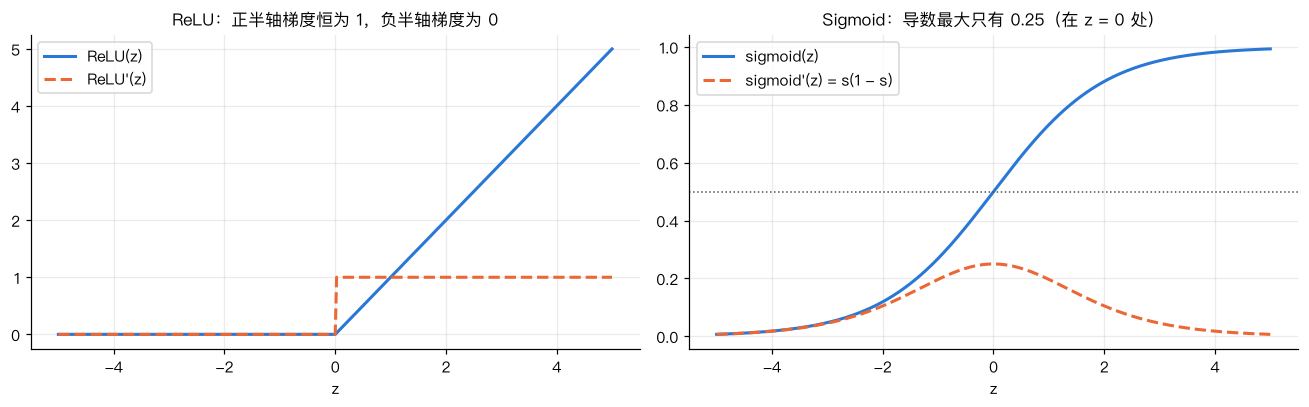

In [14]:
# 观察图 3：激活函数和它们的导数。
z_line = np.linspace(-5, 5, 401).reshape(-1, 1)
s_line = sigmoid(z_line)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(z_line, relu(z_line), color=SERIES_COLORS[0], linewidth=2, label="ReLU(z)")
axes[0].plot(z_line, relu_derivative(z_line), color=SERIES_COLORS[1], linewidth=2, linestyle="--", label="ReLU'(z)")
axes[0].set_title("ReLU：正半轴梯度恒为 1，负半轴梯度为 0")
axes[1].plot(z_line, s_line, color=SERIES_COLORS[0], linewidth=2, label="sigmoid(z)")
axes[1].plot(z_line, s_line * (1 - s_line), color=SERIES_COLORS[1], linewidth=2, linestyle="--", label="sigmoid'(z) = s(1 - s)")
axes[1].axhline(0.5, color="#52514e", linewidth=1, linestyle=":")  # 点线：sigmoid(0) = 0.5
axes[1].set_title("Sigmoid：导数最大只有 0.25（在 z = 0 处）")
for ax in axes:
    ax.set_xlabel("z")
    ax.legend()
fig.tight_layout()
plt.show()

### 3.2 Forward Propagation

**你要实现**：`forward(X, parameters)`

$$
Z^{[1]}=XW^{[1]}+b^{[1]},\qquad A^{[1]}=\operatorname{ReLU}(Z^{[1]}),\qquad
Z^{[2]}=A^{[1]}W^{[2]}+b^{[2]},\qquad \hat Y=\sigma(Z^{[2]})
$$

| 步骤 | 形状推导 |
| --- | --- |
| $XW^{[1]}$ | $(m,2)\,@\,(2,5)\to(m,5)$ |
| $+\,b^{[1]}$ | $(m,5)+(1,5)\to(m,5)$（broadcasting） |
| $A^{[1]}W^{[2]}$ | $(m,5)\,@\,(5,1)\to(m,1)$ |
| $+\,b^{[2]}$ | $(m,1)+(1,1)\to(m,1)$ |

- 返回 `(Y_hat, cache)`，其中 `cache = {"Z1": Z1, "A1": A1, "Z2": Z2, "Y_hat": Y_hat}`。`backward` 需要这些中间结果。
- 调用你自己写的 `relu` 和 `sigmoid`。
- 这里不算 loss，也不做 0.5 阈值判断。

In [15]:
def forward(
    X: np.ndarray,
    parameters: dict[str, np.ndarray],
) -> tuple[np.ndarray, dict[str, np.ndarray]]:
    """两层网络的前向传播。

    Parameters
    ----------
    X : ndarray, shape (m, n_x)
        一批样本，每行一个样本。
    parameters : dict
        initialize_parameters 返回的字典：W1, b1, W2, b2。

    Returns
    -------
    Y_hat : ndarray, shape (m, 1)
        属于 Class 1 的概率。
    cache : dict
        "Z1" (m, n_h), "A1" (m, n_h), "Z2" (m, 1), "Y_hat" (m, 1)

    Notes
    -----
    不修改 X 和 parameters，不访问全局变量。
    """
    # TODO: 取出四个参数。

    W1 = parameters["W1"]
    b1 = parameters["b1"]
    W2 = parameters["W2"]
    b2 = parameters["b2"]

    # TODO: 隐藏层：线性变换 + ReLU。
    Z1 = X @ W1 + b1
    A1 = relu(Z1)

    # TODO: 输出层：线性变换 + Sigmoid。

    Z2 = A1 @ W2 + b2
    y_hat = sigmoid(Z2)

    # TODO: 把四个中间结果放进 cache，返回 (Y_hat, cache)。
    
    cache = {}
    cache["Z1"] = Z1
    cache["A1"] = A1
    cache["Z2"] = Z2
    cache["Y_hat"] = y_hat

    return (y_hat, cache)
    # raise NotImplementedError("TODO Lab 3: implement forward")

In [16]:
# Lab 3.2 自检：4 个样本、3 个隐藏神经元，可以手算。
# 样本数 (4) 和隐藏层宽度 (3) 故意不同，转置写错时形状会对不上。
X_hand = np.array([[1.0, 2.0], [-1.0, 0.5], [0.0, -1.0], [2.0, -0.5]])
Y_hand = np.array([[1], [0], [1], [0]])
params_hand = {
    "W1": np.array([[1.0, -1.0, 0.5], [0.5, 1.0, -1.0]]),
    "b1": np.array([[0.0, 0.5, -0.5]]),
    "W2": np.array([[1.0], [-1.0], [2.0]]),
    "b2": np.array([[0.5]]),
}
params_hand_before = {k: v.copy() for k, v in params_hand.items()}

Y_hat_hand, cache_hand = forward(X_hand, params_hand)
assert set(cache_hand) == {"Z1", "A1", "Z2", "Y_hat"}, "cache 的键名应该是 Z1, A1, Z2, Y_hat"
assert cache_hand["Z1"].shape == (4, 3) and cache_hand["A1"].shape == (4, 3)
assert cache_hand["Z2"].shape == (4, 1) and Y_hat_hand.shape == (4, 1)

# 第一行：Z1 = [1*1 + 2*0.5 + 0, 1*(-1) + 2*1 + 0.5, 1*0.5 + 2*(-1) - 0.5] = [2, 1.5, -2]
np.testing.assert_allclose(cache_hand["Z1"], [[2.0, 1.5, -2.0], [-0.75, 2.0, -1.5], [-0.5, -0.5, 0.5], [1.75, -2.0, 1.0]])
np.testing.assert_allclose(cache_hand["A1"], [[2.0, 1.5, 0.0], [0.0, 2.0, 0.0], [0.0, 0.0, 0.5], [1.75, 0.0, 1.0]])
# 第一行：Z2 = 2*1 + 1.5*(-1) + 0*2 + 0.5 = 1.0
np.testing.assert_allclose(cache_hand["Z2"], [[1.0], [-1.5], [1.5], [4.25]])
np.testing.assert_allclose(Y_hat_hand, 1 / (1 + np.exp(-np.array([[1.0], [-1.5], [1.5], [4.25]]))))
np.testing.assert_allclose(cache_hand["Y_hat"], Y_hat_hand)
for k in params_hand:
    np.testing.assert_array_equal(params_hand[k], params_hand_before[k])
print("Lab 3.2 forward 自检通过。")

Lab 3.2 forward 自检通过。


In [17]:
# 用初始参数在 800 个训练样本上跑一次前向传播。
parameters_init = initialize_parameters(N_INPUT, N_HIDDEN, N_OUTPUT, seed=SEED)
Y_hat_init, cache_init = forward(X_train_std, parameters_init)
for name, value in cache_init.items():
    print(f"{name:6s} shape = {value.shape}")
print("初始预测概率：最小 = "
      f"{Y_hat_init.min():.3f}, 平均 = {Y_hat_init.mean():.3f}, 最大 = {Y_hat_init.max():.3f}")
print("每个隐藏神经元被激活（Z1 > 0）的样本比例：",
      np.round((cache_init["Z1"] > 0).mean(axis=0), 3))

Z1     shape = (800, 5)
A1     shape = (800, 5)
Z2     shape = (800, 1)
Y_hat  shape = (800, 1)
初始预测概率：最小 = 0.011, 平均 = 0.233, 最大 = 0.500
每个隐藏神经元被激活（Z1 > 0）的样本比例： [0.499 0.486 0.499 0.502 0.49 ]


## Lab 4：Loss and Backpropagation

### 4.1 Binary Cross-Entropy

**你要实现**：`compute_loss(Y, Y_hat, eps=1e-12)`

$$
J=-\frac1m\sum_{i=1}^{m}\Bigl[y_i\log(\hat y_i)+(1-y_i)\log(1-\hat y_i)\Bigr]
$$

- 先 `np.clip(Y_hat, eps, 1 - eps)` 得到新数组，不修改传入的 `Y_hat`。
- `log` 是自然对数 `np.log`。
- 返回一个 Python `float`（用 `float(...)` 转换），不要返回 `(1, 1)` 数组。
- 参考值：所有预测都等于 0.5 时，$J=\log 2\approx0.6931$，和标签无关。

In [18]:
def compute_loss(Y: np.ndarray, Y_hat: np.ndarray, eps: float = 1e-12) -> float:
    """计算平均 Binary Cross-Entropy。

    Parameters
    ----------
    Y : ndarray, shape (m, 1)
        真实标签，0 或 1。
    Y_hat : ndarray, shape (m, 1)
        预测概率，必须与 Y 同形状。
    eps : float
        裁剪常数，避免 log(0)。

    Returns
    -------
    loss : float
        所有样本的平均损失（Python float）。
    """
    # TODO: 把 Y_hat 裁剪到 [eps, 1 - eps]，得到新数组。
    Y_hat_after_clipping = np.clip(Y_hat, eps, 1-eps)
    # TODO: 按公式计算并对样本取平均，返回 Python float。
    loss = -np.mean(
        Y * np.log(Y_hat_after_clipping)
        + (1 - Y) * np.log(1 - Y_hat_after_clipping)
    )
    return float(loss)
    # raise NotImplementedError("TODO Lab 4: implement compute_loss")

In [19]:
# Lab 4.1 自检
y_loss = np.array([[0], [1]])
neutral = compute_loss(y_loss, np.array([[0.5], [0.5]]))
assert isinstance(neutral, float), "compute_loss 应返回 Python float"
np.testing.assert_allclose(neutral, np.log(2), atol=1e-12)

good = compute_loss(y_loss, np.array([[0.1], [0.9]]))
bad = compute_loss(y_loss, np.array([[0.9], [0.1]]))
assert 0.0 < good < neutral < bad
np.testing.assert_allclose(good, -np.log(0.9), atol=1e-12)

edge = np.array([[1.0], [0.0]])
edge_before = edge.copy()
assert np.isfinite(compute_loss(y_loss, edge)), "预测恰好为 0 或 1 时也要返回有限值"
np.testing.assert_array_equal(edge, edge_before)

# 沿用 Lab 3.2 的手算例子。
np.testing.assert_allclose(compute_loss(Y_hand, Y_hat_hand), 1.245062925103806, atol=1e-10)
print("Lab 4.1 compute_loss 自检通过。")
print("初始参数在训练集上的 loss：", compute_loss(y_train, Y_hat_init))

Lab 4.1 compute_loss 自检通过。
初始参数在训练集上的 loss： 1.183676341508577


### 4.2 Backpropagation

**你要实现**：`backward(X, Y, parameters, cache)`

按从输出到输入的顺序计算（推导见公式总表 4.7 节）：

| 顺序 | 公式 | 代码提示 | Shape |
| --- | --- | --- | --- |
| 1 | $dZ^{[2]}=\hat Y-Y$ | `cache["Y_hat"] - Y` | $(m,1)$ |
| 2 | $dW^{[2]}=\frac1m {A^{[1]}}^{\top}dZ^{[2]}$ | `.T`、`@`、`/ m` | $(5,1)$ |
| 3 | $db^{[2]}=\frac1m\sum_i dZ^{[2]}_{i,:}$ | `np.sum(..., axis=0, keepdims=True) / m` | $(1,1)$ |
| 4 | $dA^{[1]}=dZ^{[2]}{W^{[2]}}^{\top}$ | `@`、`.T` | $(m,5)$ |
| 5 | $dZ^{[1]}=dA^{[1]}\odot\operatorname{ReLU}'(Z^{[1]})$ | `*`、`relu_derivative(cache["Z1"])` | $(m,5)$ |
| 6 | $dW^{[1]}=\frac1m X^{\top}dZ^{[1]}$ | `.T`、`@`、`/ m` | $(2,5)$ |
| 7 | $db^{[1]}=\frac1m\sum_i dZ^{[1]}_{i,:}$ | `np.sum(..., axis=0, keepdims=True) / m` | $(1,5)$ |

- $m$ 从 `X.shape[0]` 读取，不要写死 800。
- 返回字典 `{"dW1", "db1", "dW2", "db2"}`。每个梯度的形状必须和对应参数完全相同。
- 第 4 步要用 `parameters["W2"]` 把误差传回隐藏层，第 6 步要用 `X`。这就是 `backward` 需要这两个参数的原因。
- 第 5 步是逐元素乘法 `*`，不是矩阵乘法 `@`。某个样本在某个隐藏神经元上 $Z^{[1]}\le0$ 时，这个神经元前向输出 0，反向传播时这个位置的梯度也是 0：这个神经元不会为这个样本把梯度往回传。
- 这里只算梯度，不更新参数。

In [20]:
def backward(
    X: np.ndarray,
    Y: np.ndarray,
    parameters: dict[str, np.ndarray],
    cache: dict[str, np.ndarray],
) -> dict[str, np.ndarray]:
    """用解析公式计算平均 BCE 对四个参数的梯度。

    Parameters
    ----------
    X : ndarray, shape (m, n_x)
        与 forward 使用的输入相同。
    Y : ndarray, shape (m, 1)
        真实标签。
    parameters : dict
        W1, b1, W2, b2
    cache : dict
        forward 返回的 Z1, A1, Z2, Y_hat（Y_hat 未经裁剪）。

    Returns
    -------
    grads : dict
        "dW1" (n_x, n_h), "db1" (1, n_h), "dW2" (n_h, 1), "db2" (1, 1)

    Notes
    -----
    不修改任何输入，不更新参数。
    """
    # TODO: 读取样本数 m。
    m = X.shape[0]

    # TODO: 输出层：dZ2、dW2、db2。
    dZ2 = cache["Y_hat"] - Y
    dW2 = cache["A1"].T @ dZ2 / m
    db2 = np.sum(dZ2, axis = 0, keepdims = True) / m

    # TODO: 把误差传回隐藏层：dA1、dZ1（用 relu_derivative）。
    dA1 = dZ2 @ parameters["W2"].T
    dZ1 = dA1 * relu_derivative(cache["Z1"])
    dW1 = X.T @ dZ1 / m
    db1 = np.sum(dZ1, axis = 0, keepdims = True) / m

    # TODO: 隐藏层：dW1、db1，返回 grads 字典。
    grads = {}
    grads["dW1"] = dW1
    grads["db1"] = db1
    grads["dW2"] = dW2
    grads["db2"] = db2

    return grads

    # raise NotImplementedError("TODO Lab 4: implement backward")

In [21]:
# Lab 4.2 自检：沿用 Lab 3.2 的手算例子（期望值按公式总表 4.7 节的公式算出）。
grads_hand = backward(X_hand, Y_hand, params_hand, cache_hand)
assert set(grads_hand) == {"dW1", "db1", "dW2", "db2"}
for name in ("W1", "b1", "W2", "b2"):
    assert grads_hand["d" + name].shape == params_hand[name].shape, (
        f"d{name} 的形状 {grads_hand['d' + name].shape}，应与参数相同：{params_hand[name].shape}"
    )

np.testing.assert_allclose(grads_hand["db2"], [[0.17924873789668982]], atol=1e-10)
np.testing.assert_allclose(grads_hand["dW2"], [[0.2968764524835825], [-0.00964027111056999], [0.22368090276339406]], atol=1e-10)
np.testing.assert_allclose(grads_hand["db1"], [[0.17924873789668982, 0.02162897439090969, 0.401755424575199]], atol=1e-10)
np.testing.assert_allclose(
    grads_hand["dW1"],
    [[0.42573283113587845, 0.11284173629408786, 0.9859363729567544],
     [-0.25771275730459187, 0.11166752020920301, -0.15527133133601043]],
    atol=1e-10,
)
for k in params_hand:
    np.testing.assert_array_equal(params_hand[k], params_hand_before[k])
print("Lab 4.2 backward 自检通过。")

Lab 4.2 backward 自检通过。


### 4.3 Numerical Gradient Checking

**你要实现**：`gradient_check(parameters, grads, X, Y, epsilon=1e-5)`

上面的自检只覆盖了一个例子。数值梯度检查可以在**任意**参数和数据上验证 `backward`。它只用到 `forward` 和 `compute_loss`，完全不依赖你推导的反向传播公式：

$$
g^{\text{num}}_k=\frac{J(\theta_k+\varepsilon)-J(\theta_k-\varepsilon)}{2\varepsilon},\qquad
\text{relative error}=\frac{\lVert g^{\text{num}}-g^{\text{ana}}\rVert_2}{\lVert g^{\text{num}}\rVert_2+\lVert g^{\text{ana}}\rVert_2+10^{-12}}
$$

做法：

1. 对每个参数名 `"W1"`、`"b1"`、`"W2"`、`"b2"`，准备一个 `np.zeros_like` 数组存放数值梯度。
2. 用 `np.ndindex(shape)` 遍历这个参数的每个元素位置 `idx`。
3. 把参数字典复制两份（`{k: v.copy() for ...}`），一份在 `idx` 处 `+ epsilon`，另一份 `- epsilon`。
4. 两份参数分别调用 `forward` 和 `compute_loss`，代入中心差分公式。
5. 用 `np.linalg.norm` 计算这个参数的相对误差，存进结果字典。

- 返回 `{"W1": float, "b1": float, "W2": float, "b2": float}`，每一项是一个参数的相对误差。
- 传入的 `grads` 是 `backward` 算好的解析梯度。把它作为参数传进来，就可以故意传一组错的梯度，确认检查器能发现错误。
- **必须复制**：直接修改 `parameters[name][idx]` 会改掉调用者的参数。
- 21 个参数 × 2 = 42 次前向传播，在 50 个样本上很快。但它比 `backward` 慢得多，每个 epoch 都跑一遍代价太大，所以只用来检查，不要在训练循环里调用。
- 下面的自检只要求相对误差 $<10^{-6}$，留了一些余量。正确的 `backward` 通常能得到 $10^{-10}$ 左右的误差。

In [ ]:
def gradient_check(
    parameters: dict[str, np.ndarray],
    grads: dict[str, np.ndarray],
    X: np.ndarray,
    Y: np.ndarray,
    epsilon: float = 1e-5,
) -> dict[str, float]:
    """用中心差分验证解析梯度。

    Parameters
    ----------
    parameters : dict
        W1, b1, W2, b2。函数内不能修改它。
    grads : dict
        backward 返回的解析梯度：dW1, db1, dW2, db2。
    X : ndarray, shape (m, n_x)
    Y : ndarray, shape (m, 1)
    epsilon : float
        中心差分步长。

    Returns
    -------
    relative_errors : dict
        {"W1": ..., "b1": ..., "W2": ..., "b2": ...}，每项是 Python float。
    """
    # TODO: 遍历四个参数名，为每个参数准备 numerical 数组。
    W1_zeros = np.zeros_like(W1)
    b1_zeros = np.zeros_like(b1)
    W2_zeros = np.zeros_like(W2)
    b1_zeros = np.zeros_like(b2)

    # TODO: 用 np.ndindex 遍历每个元素：复制参数，±epsilon，分别算 loss，套用中心差分。
    
    # TODO: 计算 numerical 与 grads["d" + name] 的相对误差，存成 float。
    raise NotImplementedError("TODO Lab 4: implement gradient_check")

In [67]:
# Lab 4.3 自检
errors_hand = gradient_check(params_hand, grads_hand, X_hand, Y_hand, epsilon=GRAD_CHECK_EPSILON)
assert set(errors_hand) == {"W1", "b1", "W2", "b2"}
assert all(isinstance(v, float) for v in errors_hand.values()), "每个相对误差应是 Python float"
assert max(errors_hand.values()) < 1e-6, f"正确的梯度应该得到很小的误差：{errors_hand}"

# 故意把 dW1 放大一倍，检查器必须发现。
grads_wrong = {k: v.copy() for k, v in grads_hand.items()}
grads_wrong["dW1"] = grads_wrong["dW1"] * 2
errors_wrong = gradient_check(params_hand, grads_wrong, X_hand, Y_hand, epsilon=GRAD_CHECK_EPSILON)
assert errors_wrong["W1"] > 1e-2, "错误的 dW1 没有被发现"
assert errors_wrong["W2"] < 1e-6, "只有 W1 的误差应该变大"

for k in params_hand:
    np.testing.assert_array_equal(params_hand[k], params_hand_before[k], err_msg="gradient_check 不能修改参数")
print("Lab 4.3 gradient_check 自检通过。")
print("正确梯度：", {k: f"{v:.2e}" for k, v in errors_hand.items()})
print("错误梯度：", {k: f"{v:.2e}" for k, v in errors_wrong.items()})

NameError: name 'gradient_check' is not defined

In [ ]:
# 在真实数据（前 50 个训练样本）和 He 初始化参数上做梯度检查，并画出结果。
X_gc, Y_gc = X_train_std[:50], y_train[:50]
parameters_gc = initialize_parameters(N_INPUT, N_HIDDEN, N_OUTPUT, seed=SEED)
_, cache_gc = forward(X_gc, parameters_gc)
grads_gc = backward(X_gc, Y_gc, parameters_gc, cache_gc)
errors_gc = gradient_check(parameters_gc, grads_gc, X_gc, Y_gc, epsilon=GRAD_CHECK_EPSILON)

names = list(errors_gc)
values = [max(errors_gc[n], 1e-16) for n in names]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(names, values, color=SERIES_COLORS[0], width=0.55)
ax.axhline(1e-7, color="#0ca30c", linestyle="--", linewidth=1.5, label="1e-7: 正确")
ax.axhline(1e-4, color="#d03b3b", linestyle="--", linewidth=1.5, label="1e-4: 很可能有 bug")
ax.set_yscale("log")
ax.set_ylim(1e-14, 1)
for i, v in enumerate(values):
    ax.text(i, v * 2, f"{v:.1e}", ha="center", fontsize=9, color="#52514e")
ax.set_ylabel("相对误差（对数坐标）")
ax.set_title("Numerical Gradient Check：真实数据上的 backward")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

assert max(errors_gc.values()) < 1e-6, f"真实数据上的梯度检查没有通过：{errors_gc}"
print("真实数据上的梯度检查通过。")

## Lab 5：Training Loop

### 5.1 参数更新

**你要实现**：`update_parameters(parameters, grads, learning_rate)`

$$
W^{[l]}\leftarrow W^{[l]}-\alpha\,dW^{[l]},\qquad b^{[l]}\leftarrow b^{[l]}-\alpha\,db^{[l]}
$$

- 返回一个**新的**参数字典，不原地修改传入的数组。这样更新前后的参数可以直接比较，调试也更容易。
- 是减号。梯度指向 loss 增长最快的方向，所以沿相反方向走，loss 才会下降。
- 梯度在 `backward` 里已经除过 $m$，这里不要再除。

In [22]:
def update_parameters(
    parameters: dict[str, np.ndarray],
    grads: dict[str, np.ndarray],
    learning_rate: float,
) -> dict[str, np.ndarray]:
    """执行一次 Gradient Descent 更新，返回新的参数字典。

    Parameters
    ----------
    parameters : dict
        W1, b1, W2, b2
    grads : dict
        dW1, db1, dW2, db2（形状与对应参数相同）
    learning_rate : float
        学习率 alpha，大于 0。

    Returns
    -------
    new_parameters : dict
        与 parameters 相同的键和形状。

    Notes
    -----
    不原地修改 parameters 中的数组。
    """
    # TODO: 对每个参数 name，用 grads["d" + name] 计算新值，放进新字典并返回。
    new_parameters = {}
    new_parameters["W1"] = parameters["W1"] - learning_rate * grads["dW1"]
    new_parameters["b1"] = parameters["b1"] - learning_rate * grads["db1"]
    new_parameters["W2"] = parameters["W2"] - learning_rate * grads["dW2"]
    new_parameters["b2"] = parameters["b2"] - learning_rate * grads["db2"]

    return new_parameters
    # raise NotImplementedError("TODO Lab 5: implement update_parameters")

In [23]:
# Lab 5.1 自检
p_old = {"W1": np.array([[1.0, -2.0]]), "b1": np.array([[0.5, 0.0]]),
         "W2": np.array([[2.0], [1.0]]), "b2": np.array([[-1.0]])}
g_step = {"dW1": np.array([[0.2, -0.4]]), "db1": np.array([[-0.1, 0.3]]),
          "dW2": np.array([[1.0], [0.0]]), "db2": np.array([[0.5]])}
p_old_snapshot = {k: v.copy() for k, v in p_old.items()}

p_new = update_parameters(p_old, g_step, learning_rate=0.1)
assert set(p_new) == set(p_old)
np.testing.assert_allclose(p_new["W1"], [[0.98, -1.96]])
np.testing.assert_allclose(p_new["b1"], [[0.51, -0.03]])
np.testing.assert_allclose(p_new["W2"], [[1.9], [1.0]])
np.testing.assert_allclose(p_new["b2"], [[-1.05]])
for k in p_old:
    np.testing.assert_array_equal(p_old[k], p_old_snapshot[k], err_msg="不能原地修改输入")
print("Lab 5.1 update_parameters 自检通过。")

Lab 5.1 update_parameters 自检通过。


### 5.2 训练循环

**你要实现**：`train(X, Y, n_hidden=5, learning_rate=0.05, epochs=5000, log_every=100, seed=42, verbose=True)`

每个 epoch 用全部训练数据（Batch Gradient Descent）：

```text
parameters = initialize_parameters(X.shape[1], n_hidden, Y.shape[1], seed=seed)   # 只在循环前执行一次
for epoch in range(epochs):
    1. Forward：Y_hat, cache = forward(X, parameters)
    2. 如果 epoch % log_every == 0：用这次的 Y_hat 计算 loss，记入 history；verbose=True 时打印
    3. Backward：grads = backward(X, Y, parameters, cache)
    4. Update：parameters = update_parameters(parameters, grads, learning_rate)
```

**history 约定**：

- 返回 `history = {"epoch": [...], "loss": [...]}`，两个列表一样长。
- 记录的是第 `epoch` 次更新**之前**的 loss，所以第一项一定是 `epoch = 0`、初始参数下的 loss。
- `epochs=5000`、`log_every=100` 时一共记录 50 次：`0, 100, ..., 4900`。
- 返回的 `parameters` 是全部更新完成后的参数。它对应的 loss 需要训练结束后再算一次，通常比 `history["loss"][-1]` 略小。

**初始化约定**：必须通过 `initialize_parameters(X.shape[1], n_hidden, Y.shape[1], seed=seed)` 初始化。Lab 6 会用相同的 seed 重建第 0 个 epoch 的参数，画出训练过程的演化。

In [30]:
def train(
    X: np.ndarray,
    Y: np.ndarray,
    n_hidden: int = 5,
    learning_rate: float = 0.05,
    epochs: int = 5000,
    log_every: int = 100,
    seed: int | None = 42,
    verbose: bool = True,
) -> tuple[dict[str, np.ndarray], dict[str, list]]:
    """用 Batch Gradient Descent 训练两层网络。

    Parameters
    ----------
    X : ndarray, shape (m, n_x)
        标准化后的训练特征。
    Y : ndarray, shape (m, 1)
        训练标签。
    n_hidden : int
        隐藏层宽度。
    learning_rate : float
        学习率 alpha。
    epochs : int
        训练轮数；每轮更新一次参数。
    log_every : int
        每隔多少个 epoch 记录一次 loss。
    seed : int or None
        传给 initialize_parameters。
    verbose : bool
        为 True 时在每个记录点打印 epoch 和 loss。

    Returns
    -------
    parameters : dict
        训练结束后的 W1, b1, W2, b2。
    history : dict
        {"epoch": list[int], "loss": list[float]}，记录更新前的 loss。

    Notes
    -----
    复用前面实现的函数，不在这里另写一套前向 / 反向逻辑。
    """
    # TODO: 初始化参数（只一次）和 history。
    parameters = initialize_parameters(X.shape[1], n_hidden, Y.shape[1], seed=seed)
    history = {"epoch": [], "loss": []}
    # TODO: 循环 epochs 次：forward → (按间隔) 记录 loss → backward → update。
    for epoch in range(epochs):
        Y_hat, cache = forward(X, parameters)
        if epoch % log_every == 0:
            history["epoch"].append(epoch)
            loss = compute_loss(Y, Y_hat)
            history["loss"].append(loss)
            
    # TODO: verbose=True 时打印，例如 f"epoch {epoch:5d} | loss {loss:.6f}"。
        if verbose:
            print(f"epoch {epoch:5d} | loss {loss:.6f}")
        grads = backward(X, Y, parameters = parameters, cache = cache)
        parameters = update_parameters(parameters=parameters, grads= grads, learning_rate = learning_rate)
    # TODO: 返回 (parameters, history)。
    return (parameters, history)
    # raise NotImplementedError("TODO Lab 5: implement train")

In [31]:
# Lab 5.2 自检：6 个点的小数据集，与正式数据无关。
X_tiny = np.array([[-1.0, -1.0], [-1.0, 1.0], [1.0, -1.0], [1.0, 1.0], [0.5, 0.2], [-0.3, -0.8]])
Y_tiny = np.array([[0], [1], [1], [1], [1], [0]])

# 1 个 epoch：检查记录时机，以及参数是否恰好更新了一次。
p_one, h_one = train(X_tiny, Y_tiny, n_hidden=4, learning_rate=0.5, epochs=1, log_every=1, seed=0, verbose=False)
p_start = initialize_parameters(2, 4, 1, seed=0)
Y_hat_start, cache_start = forward(X_tiny, p_start)
assert h_one["epoch"] == [0]
np.testing.assert_allclose(h_one["loss"][0], compute_loss(Y_tiny, Y_hat_start))
p_expected = update_parameters(p_start, backward(X_tiny, Y_tiny, p_start, cache_start), 0.5)
for k in p_expected:
    np.testing.assert_allclose(p_one[k], p_expected[k], err_msg=f"一个 epoch 后的 {k} 不对")

# 多个 epoch：记录点、长度、loss 下降、可复现。
p_tiny, h_tiny = train(X_tiny, Y_tiny, n_hidden=4, learning_rate=0.5, epochs=250, log_every=50, seed=0, verbose=False)
assert h_tiny["epoch"] == [0, 50, 100, 150, 200], h_tiny["epoch"]
assert len(h_tiny["loss"]) == 5
assert all(isinstance(v, float) for v in h_tiny["loss"])
assert h_tiny["loss"][-1] < h_tiny["loss"][0]
p_tiny_again, h_tiny_again = train(X_tiny, Y_tiny, n_hidden=4, learning_rate=0.5, epochs=250, log_every=50, seed=0, verbose=False)
np.testing.assert_allclose(h_tiny["loss"], h_tiny_again["loss"])
print("verbose=True 的输出示例：")
train(X_tiny, Y_tiny, n_hidden=4, learning_rate=0.5, epochs=101, log_every=50, seed=0, verbose=True)
print("Lab 5.2 train 自检通过。")

verbose=True 的输出示例：
epoch     0 | loss 0.455296
epoch     1 | loss 0.455296
epoch     2 | loss 0.455296
epoch     3 | loss 0.455296
epoch     4 | loss 0.455296
epoch     5 | loss 0.455296
epoch     6 | loss 0.455296
epoch     7 | loss 0.455296
epoch     8 | loss 0.455296
epoch     9 | loss 0.455296
epoch    10 | loss 0.455296
epoch    11 | loss 0.455296
epoch    12 | loss 0.455296
epoch    13 | loss 0.455296
epoch    14 | loss 0.455296
epoch    15 | loss 0.455296
epoch    16 | loss 0.455296
epoch    17 | loss 0.455296
epoch    18 | loss 0.455296
epoch    19 | loss 0.455296
epoch    20 | loss 0.455296
epoch    21 | loss 0.455296
epoch    22 | loss 0.455296
epoch    23 | loss 0.455296
epoch    24 | loss 0.455296
epoch    25 | loss 0.455296
epoch    26 | loss 0.455296
epoch    27 | loss 0.455296
epoch    28 | loss 0.455296
epoch    29 | loss 0.455296
epoch    30 | loss 0.455296
epoch    31 | loss 0.455296
epoch    32 | loss 0.455296
epoch    33 | loss 0.455296
epoch    34 | loss 0.455296


### 5.3 在 800 个训练样本上训练

下面用第 3 节的配置训练。只把训练集传给 `train`，测试集留到 Lab 6 再用。

In [32]:
parameters, history = train(
    X_train_std,
    y_train,
    n_hidden=N_HIDDEN,
    learning_rate=LEARNING_RATE,
    epochs=EPOCHS,
    log_every=LOG_EVERY,
    seed=SEED,
    verbose=True,
)

assert history["epoch"] == list(range(0, EPOCHS, LOG_EVERY))  # 默认配置下是 0, 100, ..., 4900（共 50 项）
assert all(np.isfinite(history["loss"]))
final_train_loss = compute_loss(y_train, forward(X_train_std, parameters)[0])
print(f"\n训练后的训练集 loss：{final_train_loss:.6f}")

epoch     0 | loss 1.183676
epoch     1 | loss 1.183676
epoch     2 | loss 1.183676
epoch     3 | loss 1.183676
epoch     4 | loss 1.183676
epoch     5 | loss 1.183676
epoch     6 | loss 1.183676
epoch     7 | loss 1.183676
epoch     8 | loss 1.183676
epoch     9 | loss 1.183676
epoch    10 | loss 1.183676
epoch    11 | loss 1.183676
epoch    12 | loss 1.183676
epoch    13 | loss 1.183676
epoch    14 | loss 1.183676
epoch    15 | loss 1.183676
epoch    16 | loss 1.183676
epoch    17 | loss 1.183676
epoch    18 | loss 1.183676
epoch    19 | loss 1.183676
epoch    20 | loss 1.183676
epoch    21 | loss 1.183676
epoch    22 | loss 1.183676
epoch    23 | loss 1.183676
epoch    24 | loss 1.183676
epoch    25 | loss 1.183676
epoch    26 | loss 1.183676
epoch    27 | loss 1.183676
epoch    28 | loss 1.183676
epoch    29 | loss 1.183676
epoch    30 | loss 1.183676
epoch    31 | loss 1.183676
epoch    32 | loss 1.183676
epoch    33 | loss 1.183676
epoch    34 | loss 1.183676
epoch    35 | loss 1

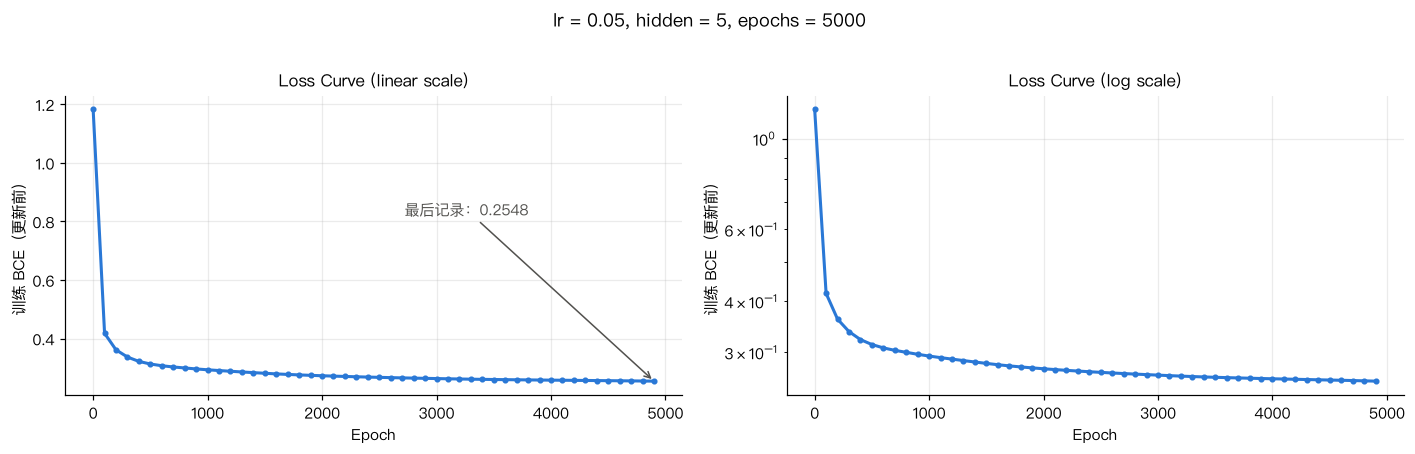

In [33]:
# 观察图 4：Loss Curve。左图是线性坐标，右图是对数坐标，后期的缓慢下降在右图更容易看清。
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, scale in zip(axes, ["linear", "log"]):
    ax.plot(history["epoch"], history["loss"], color=SERIES_COLORS[0], linewidth=2, marker="o", markersize=3)
    ax.set_yscale(scale)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("训练 BCE（更新前）")
    ax.set_title(f"Loss Curve ({scale} scale)")
axes[0].annotate(
    f"最后记录：{history['loss'][-1]:.4f}",
    xy=(history["epoch"][-1], history["loss"][-1]),
    xytext=(0.55, 0.6), textcoords="axes fraction",
    arrowprops={"arrowstyle": "->", "color": "#52514e"}, color="#52514e",
)
fig.suptitle(f"lr = {LEARNING_RATE}, hidden = {N_HIDDEN}, epochs = {EPOCHS}", y=1.02)
fig.tight_layout()
plt.show()

## Lab 6：Evaluation and Visualization

### 6.1 预测与准确率

**你要实现**：`predict_proba(X, parameters)`、`predict(X, parameters, threshold=0.5)`、`accuracy(Y, Y_pred)`

$$
\hat Y=\text{forward}(X)\ \text{的第一个返回值},\qquad
\hat y^{\text{class}}_i=\mathbb 1[\hat y_i\ge 0.5],\qquad
\text{Accuracy}=\frac1m\sum_{i=1}^{m}\mathbb 1\!\left[\hat y^{\text{class}}_i=y_i\right]
$$

- `predict_proba` 返回概率，形状 `(m, 1)`。直接复用 `forward`。
- `predict` 返回 0/1 **整数**列向量。约定概率**恰好等于**阈值时归为 1（用 `>=`）。
- `accuracy` 返回 `[0, 1]` 之间的 Python `float`。先检查两个数组形状相同，不同就 `raise ValueError`，避免 `(m, 1)` 和 `(m,)` 悄悄广播成 `(m, m)`。
- API：比较运算、`.astype(int)`、`np.mean`、`float`。

In [35]:
def predict_proba(X: np.ndarray, parameters: dict[str, np.ndarray]) -> np.ndarray:
    """返回属于 Class 1 的概率，shape (m, 1)。"""
    # TODO: 复用 forward，只返回概率。
    return forward(X, parameters= parameters)[0]
    # raise NotImplementedError("TODO Lab 6: implement predict_proba")


def predict(X: np.ndarray, parameters: dict[str, np.ndarray], threshold: float = 0.5) -> np.ndarray:
    """返回 0/1 整数标签，shape (m, 1)；概率 >= threshold 时为 1。"""
    # TODO: 概率与阈值比较，再转成 int。
    bool_arr = forward(X, parameters= parameters)[0] >= threshold
    return bool_arr.astype(int)
    # raise NotImplementedError("TODO Lab 6: implement predict")


def accuracy(Y: np.ndarray, Y_pred: np.ndarray) -> float:
    """返回预测正确的比例（Python float，范围 [0, 1]）。

    Y 与 Y_pred 形状不同时抛出 ValueError。
    """
    # TODO: 先检查形状，再比较并取平均。
    if not Y.shape == Y_pred.shape:
        raise ValueError
    return np.mean((Y == Y_pred).astype(int))
    # raise NotImplementedError("TODO Lab 6: implement accuracy")

In [36]:
# Lab 6.1 自检
proba_hand = predict_proba(X_hand, params_hand)
assert proba_hand.shape == (4, 1)
np.testing.assert_allclose(proba_hand, Y_hat_hand)

pred_hand = predict(X_hand, params_hand)
assert pred_hand.shape == (4, 1)
assert np.issubdtype(pred_hand.dtype, np.integer), "predict 应返回整数数组"
np.testing.assert_array_equal(pred_hand, [[1], [0], [1], [1]])
np.testing.assert_array_equal(predict(X_hand, params_hand, threshold=0.8), [[0], [0], [1], [1]])

# 概率恰好为 0.5（Z2 = 0）时归为 1。
params_half = {k: np.zeros_like(v) for k, v in params_hand.items()}
np.testing.assert_array_equal(predict(X_hand, params_half), [[1], [1], [1], [1]])

acc_hand = accuracy(Y_hand, pred_hand)
assert isinstance(acc_hand, float)
np.testing.assert_allclose(acc_hand, 0.75)
try:
    accuracy(Y_hand.ravel(), pred_hand)
except ValueError:
    pass
else:
    raise AssertionError("形状不同的标签必须抛出 ValueError")
print("Lab 6.1 自检通过。")

Lab 6.1 自检通过。


In [37]:
# 用训练后的参数评估训练集和测试集。
train_proba = predict_proba(X_train_std, parameters)
test_proba = predict_proba(X_test_std, parameters)
train_acc = accuracy(y_train, predict(X_train_std, parameters))
test_acc = accuracy(y_test, predict(X_test_std, parameters))

print(f"Train BCE: {compute_loss(y_train, train_proba):.4f}   Train Accuracy: {train_acc:.2%}")
print(f"Test  BCE: {compute_loss(y_test, test_proba):.4f}   Test  Accuracy: {test_acc:.2%}")

Train BCE: 0.2544   Train Accuracy: 87.50%
Test  BCE: 0.1849   Test  Accuracy: 91.00%


### 6.2 观察工具（已提供）

下面的代码都是**观察工具**，不属于练习。它们只调用你实现的函数。

- `plot_decision_boundary(predict_proba_fn, X, Y, ...)`：在平面上铺一层密集网格，对每个网格点算出 $\hat y$，用颜色表示概率，用黑线画出 $\hat y=0.5$ 的决策边界，并把分错的样本圈出来。它接收的是一个"输入 `(k, 2)`、输出 `(k, 1)` 概率"的函数，所以神经网络和 Logistic Regression 都能用它来画。
- `train_logistic_regression_baseline(...)`：手写的 Logistic Regression 模型，没有隐藏层（就是你在 C1_W3 实现过的那个模型），作为线性模型的对照。它复用你的 `sigmoid`，用和神经网络相同的学习率和 epoch 数训练。

坐标轴使用标准化后的特征，也就是模型实际看到的输入空间。

In [38]:
def plot_decision_boundary(
    predict_proba_fn,
    X_points: np.ndarray,
    Y_points: np.ndarray,
    ax=None,
    title: str = "",
    resolution: int = 300,
    padding: float = 0.5,
    highlight_errors: bool = True,
):
    """画概率背景、决策边界和样本点。

    predict_proba_fn : 函数，输入 (k, 2)，返回 (k, 1) 的 Class 1 概率。
    """
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5))
    x_min, x_max = X_points[:, 0].min() - padding, X_points[:, 0].max() + padding
    y_min, y_max = X_points[:, 1].min() - padding, X_points[:, 1].max() + padding
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, resolution), np.linspace(y_min, y_max, resolution))
    grid = np.c_[xx.ravel(), yy.ravel()]
    proba = predict_proba_fn(grid).reshape(xx.shape)

    filled = ax.contourf(xx, yy, proba, levels=np.linspace(0, 1, 21), cmap=PROBA_CMAP, alpha=0.75)
    ax.contour(xx, yy, proba, levels=[0.5], colors="#0b0b0b", linewidths=2)
    scatter_classes(ax, X_points, Y_points, size=16, alpha=0.9)

    if highlight_errors:
        wrong = ((predict_proba_fn(X_points) >= 0.5).astype(int) != Y_points).ravel()
        ax.scatter(X_points[wrong, 0], X_points[wrong, 1], s=70, facecolors="none",
                   edgecolors="#0b0b0b", linewidths=1.2, label=f"分错 ({wrong.sum()})")
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel("x1 (standardized)")
    ax.set_ylabel("x2 (standardized)")
    ax.set_title(title)
    ax.grid(False)
    ax.legend(loc="lower left", fontsize=8, framealpha=0.85)
    return filled


def train_logistic_regression_baseline(
    X: np.ndarray, Y: np.ndarray, learning_rate: float = LEARNING_RATE, epochs: int = EPOCHS
) -> tuple[np.ndarray, np.ndarray]:
    """手写 Logistic Regression 基线（没有隐藏层），复用你的 sigmoid。"""
    m, n_x = X.shape
    W = np.zeros((n_x, 1))
    b = np.zeros((1, 1))
    for _ in range(epochs):
        dZ = sigmoid(X @ W + b) - Y
        W = W - learning_rate * (X.T @ dZ) / m
        b = b - learning_rate * np.sum(dZ, axis=0, keepdims=True) / m
    return W, b


W_lr, b_lr = train_logistic_regression_baseline(X_train_std, y_train)


def lr_predict_proba(X_points: np.ndarray) -> np.ndarray:
    return sigmoid(X_points @ W_lr + b_lr)


def nn_predict_proba(X_points: np.ndarray) -> np.ndarray:
    return predict_proba(X_points, parameters)


lr_train_acc = accuracy(y_train, (lr_predict_proba(X_train_std) >= 0.5).astype(int))
lr_test_acc = accuracy(y_test, (lr_predict_proba(X_test_std) >= 0.5).astype(int))
print(f"Logistic Regression  Train: {lr_train_acc:.2%}   Test: {lr_test_acc:.2%}")
print(f"Two-Layer NN         Train: {train_acc:.2%}   Test: {test_acc:.2%}")

Logistic Regression  Train: 85.75%   Test: 92.00%
Two-Layer NN         Train: 87.50%   Test: 91.00%


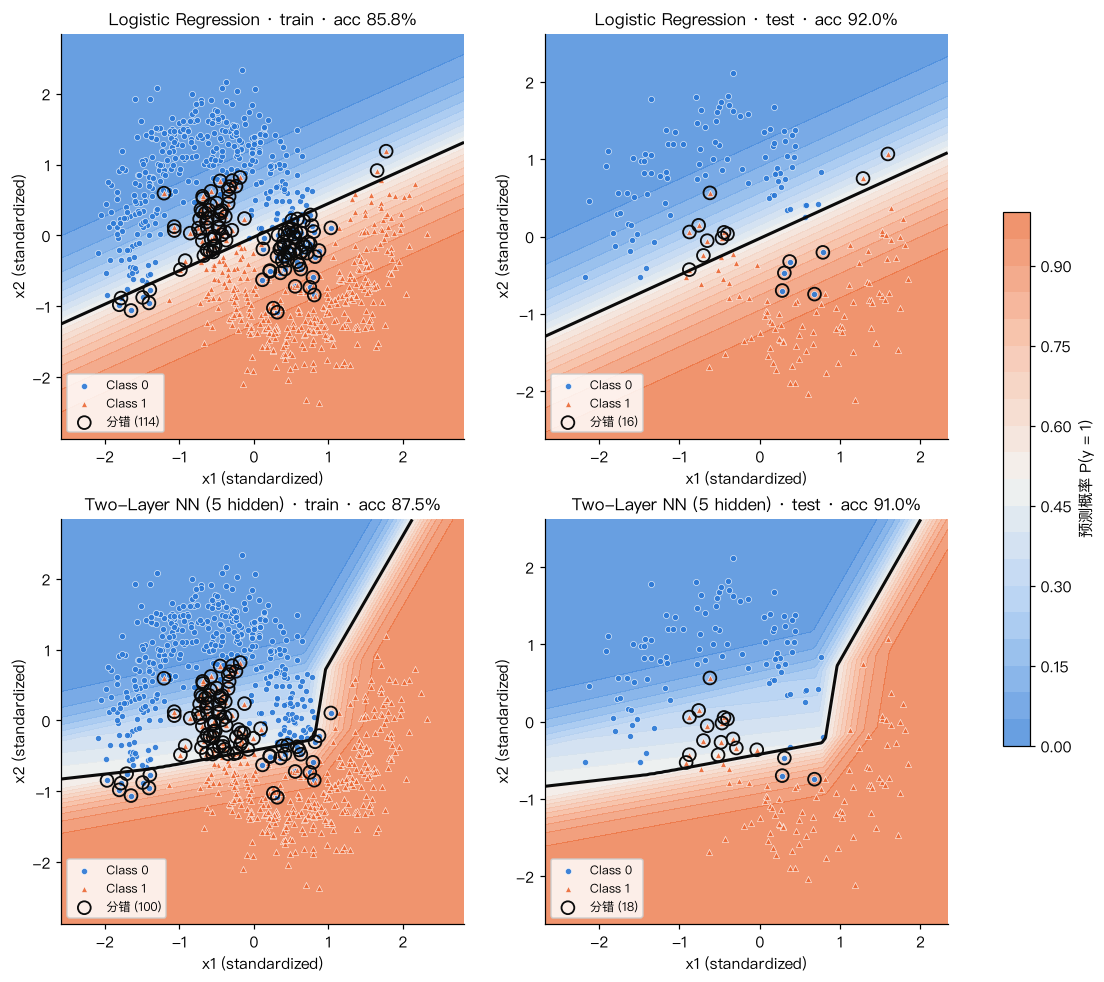

In [39]:
# 观察图 5：Logistic Regression（直线）和 Two-Layer NN（折线）的决策边界对比。
fig, axes = plt.subplots(2, 2, figsize=(13, 10.5))
plot_decision_boundary(lr_predict_proba, X_train_std, y_train, ax=axes[0, 0],
                       title=f"Logistic Regression · train · acc {lr_train_acc:.1%}")
plot_decision_boundary(lr_predict_proba, X_test_std, y_test, ax=axes[0, 1],
                       title=f"Logistic Regression · test · acc {lr_test_acc:.1%}")
plot_decision_boundary(nn_predict_proba, X_train_std, y_train, ax=axes[1, 0],
                       title=f"Two-Layer NN ({N_HIDDEN} hidden) · train · acc {train_acc:.1%}")
filled = plot_decision_boundary(nn_predict_proba, X_test_std, y_test, ax=axes[1, 1],
                                title=f"Two-Layer NN ({N_HIDDEN} hidden) · test · acc {test_acc:.1%}")
fig.colorbar(filled, ax=axes, shrink=0.6, label="预测概率 P(y = 1)")
plt.show()

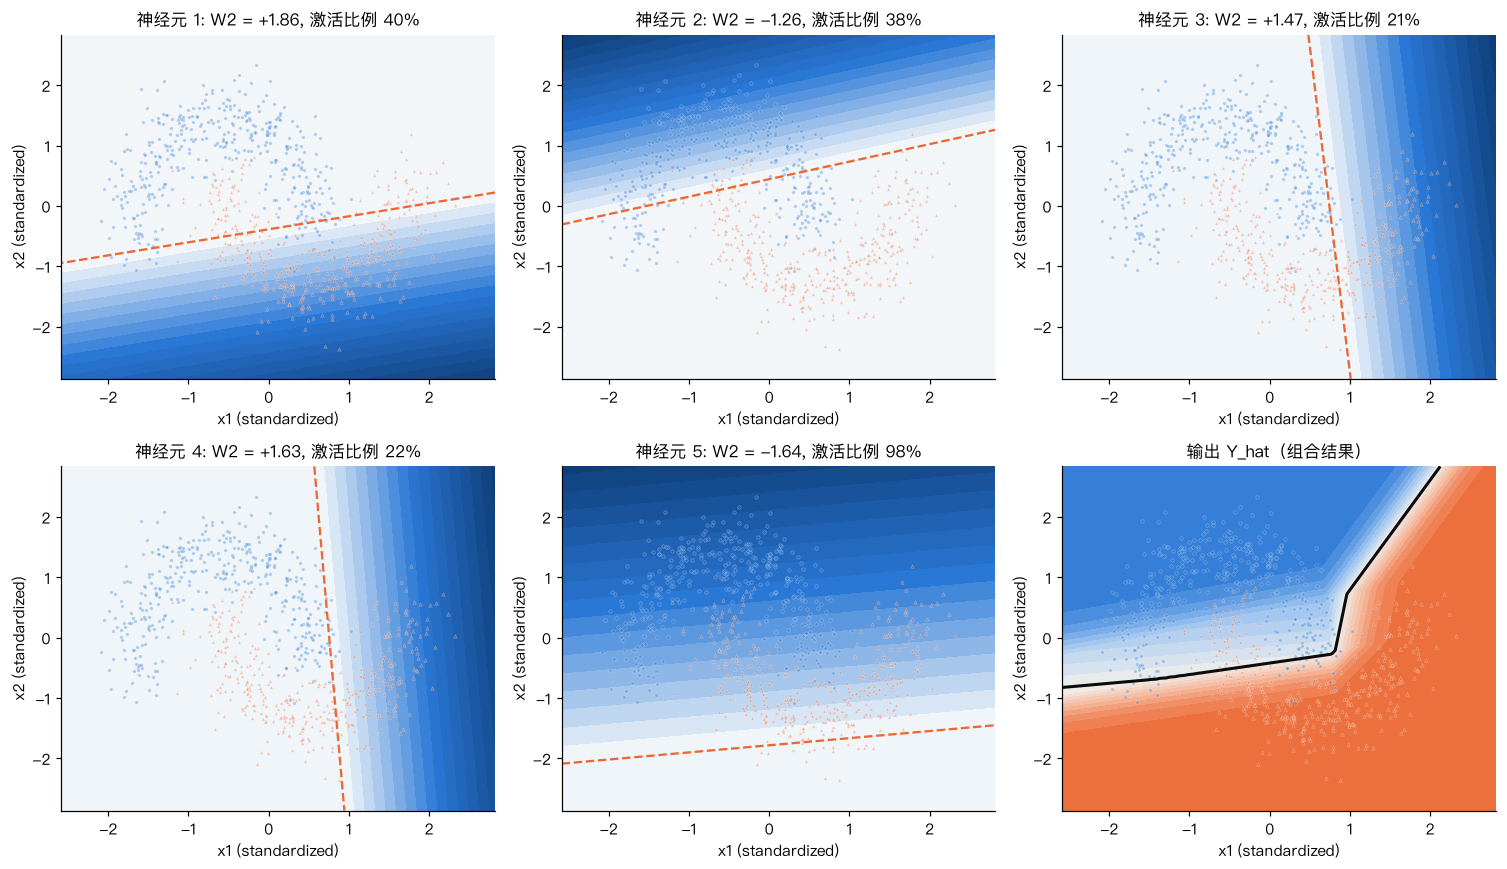

In [40]:
# 观察图 6：每个隐藏神经元"看到"了什么。
# 每个子图是一个神经元的激活值 A1_j = ReLU(x · W1[:, j] + b1[j])：虚线一侧为 0，另一侧线性增长。
# W2[j] 的正负决定这个神经元把输出推向 Class 1（+）还是 Class 0（−）。最后一个子图是它们组合后的输出概率。
pad = 0.5
gx, gy = np.meshgrid(
    np.linspace(X_train_std[:, 0].min() - pad, X_train_std[:, 0].max() + pad, 250),
    np.linspace(X_train_std[:, 1].min() - pad, X_train_std[:, 1].max() + pad, 250),
)
grid_points = np.c_[gx.ravel(), gy.ravel()]
_, grid_cache = forward(grid_points, parameters)

n_panels = N_HIDDEN + 1
n_cols = 3
n_rows = int(np.ceil(n_panels / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.6 * n_cols, 4 * n_rows))
axes = np.atleast_1d(axes).ravel()
for j in range(N_HIDDEN):
    ax = axes[j]
    act = grid_cache["A1"][:, j].reshape(gx.shape)
    ax.contourf(gx, gy, act, levels=20, cmap=ACTIVATION_CMAP)
    if act.max() > 0 and act.min() == 0:
        ax.contour(gx, gy, grid_cache["Z1"][:, j].reshape(gx.shape), levels=[0], colors="#eb6834", linestyles="--", linewidths=1.5)
    scatter_classes(ax, X_train_std, y_train, size=5, alpha=0.35)
    w2 = parameters["W2"][j, 0]
    active = (forward(X_train_std, parameters)[1]["Z1"][:, j] > 0).mean()
    ax.set_title(f"神经元 {j + 1}: W2 = {w2:+.2f}, 激活比例 {active:.0%}")
    ax.set_xlabel("x1 (standardized)")
    ax.set_ylabel("x2 (standardized)")
    ax.grid(False)
ax = axes[N_HIDDEN]
ax.contourf(gx, gy, grid_cache["Y_hat"].reshape(gx.shape), levels=np.linspace(0, 1, 21), cmap=PROBA_CMAP)
ax.contour(gx, gy, grid_cache["Y_hat"].reshape(gx.shape), levels=[0.5], colors="#0b0b0b", linewidths=2)
scatter_classes(ax, X_train_std, y_train, size=5, alpha=0.35)
ax.set_title("输出 Y_hat（组合结果）")
ax.set_xlabel("x1 (standardized)")
ax.set_ylabel("x2 (standardized)")
ax.grid(False)
for ax in axes[n_panels:]:
    ax.axis("off")
fig.tight_layout()
plt.show()

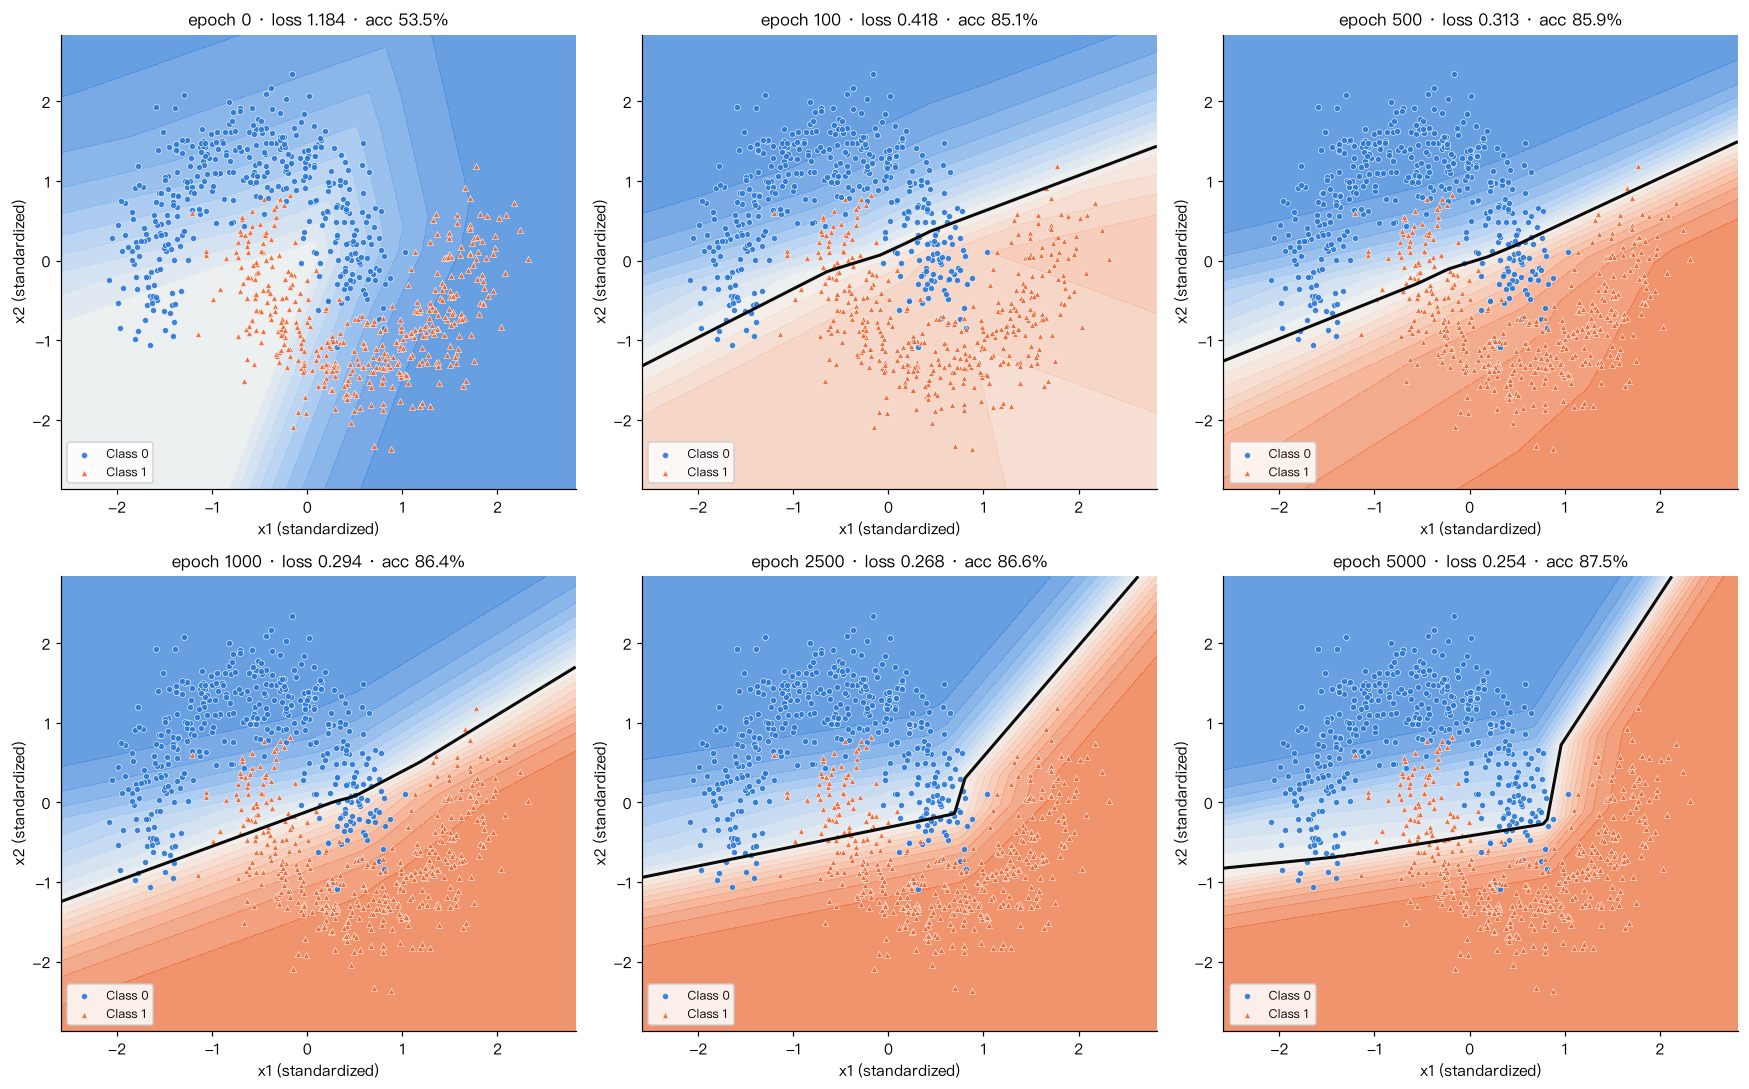

In [41]:
# 观察图 7：决策边界在训练过程中怎样变化。
# 同一个 seed 下 train(epochs=k) 正好是完整训练的前 k 步，所以可以直接重新训练到不同的 epoch。
snapshot_epochs = [0, 100, 500, 1000, 2500, EPOCHS]
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, k in zip(axes.ravel(), snapshot_epochs):
    if k == 0:
        params_k = initialize_parameters(N_INPUT, N_HIDDEN, N_OUTPUT, seed=SEED)
    else:
        params_k, _ = train(X_train_std, y_train, n_hidden=N_HIDDEN, learning_rate=LEARNING_RATE,
                            epochs=k, log_every=LOG_EVERY, seed=SEED, verbose=False)
    acc_k = accuracy(y_train, predict(X_train_std, params_k))
    loss_k = compute_loss(y_train, predict_proba(X_train_std, params_k))
    plot_decision_boundary(lambda P, p=params_k: predict_proba(P, p), X_train_std, y_train, ax=ax,
                           title=f"epoch {k} · loss {loss_k:.3f} · acc {acc_k:.1%}", highlight_errors=False)
fig.tight_layout()
plt.show()

## 7. 实验：改变配置，观察结果

**先对照一下你的结果。** 实现正确时，默认配置（5 个隐藏神经元，lr = 0.05，5,000 epochs）最后记录的训练 loss 约为 0.255，训练准确率 87.5%，测试准确率 91.0%。Logistic Regression 基线是训练 85.75%、测试 92.0%，网络暂时没有明显更好。图 5 里网络的决策边界只由几段直线组成，没有绕进两个月牙中间。

**这不是 bug。** 看图 4 的 Loss Curve：loss 在前几百个 epoch 下降很快，之后几千个 epoch 只降了一点（平台期）。到第 5,000 个 epoch，训练还停在这个平台期里。另外，图 6 里有一个神经元（神经元 5）对大约 98% 的样本都处于激活状态。神经元只在自己 $Z^{[1]}=0$ 的那条直线处让边界转弯；ReLU 在激活一侧就是 $z$ 本身，所以一个几乎总是激活的神经元在数据范围内基本就是一个线性函数，对弯曲边界几乎没有帮助。下面的实验用来验证这个解释。

请先写下你的预测，再运行实验：

1. **学习率**：lr 从 0.005 增加到 2.0，loss 曲线会怎样变化？lr 太大时会发生什么？（如果 2.0 下没看到明显问题，可以在 `LEARNING_RATES` 里再加上 10、20 试试。sigmoid 不是数值稳定版本时，可能会看到溢出警告。）
2. **隐藏层宽度**：1、2、5、10、20、50 个隐藏神经元的决策边界分别是什么形状？从几个神经元开始能分开两个月牙？
3. **训练时长**：保持 lr = 0.05，把 `EPOCHS` 改成 20,000，loss 平台期之后发生了什么？（在第 3 节的配置单元格里改，然后从那个单元格往下重新运行。训练时间大约变成原来的 4 倍。）

每个实验只改一个变量。所有实验都只看训练集来决定配置；测试集准确率只用来报告结果。

**拓展（自己动手改代码）**：把隐藏层激活换成 Tanh。需要改三处：`forward` 中的 $A^{[1]}=\tanh(Z^{[1]})$；`backward` 中的导数 $1-{A^{[1]}}^2$；初始化改用 Xavier，它的简单形式是 $\mathcal N(0, 1/n_{\text{in}})$（Glorot 的原始版本用 $2/(n_{\text{in}}+n_{\text{out}})$）。建议复制函数改名，例如 `forward_tanh`，不要直接覆盖已经通过自检的版本。

In [ ]:
# 实验 1：学习率对比（隐藏层固定为 N_HIDDEN）。可以修改 LEARNING_RATES 再运行。
LEARNING_RATES = [0.005, 0.05, 0.5, 2.0]

fig, ax = plt.subplots(figsize=(9, 4.5))
for color, lr in zip(SERIES_COLORS, LEARNING_RATES):
    params_lr, hist_lr = train(X_train_std, y_train, n_hidden=N_HIDDEN, learning_rate=lr,
                               epochs=EPOCHS, log_every=LOG_EVERY, seed=SEED, verbose=False)
    tr = accuracy(y_train, predict(X_train_std, params_lr))
    te = accuracy(y_test, predict(X_test_std, params_lr))
    ax.plot(hist_lr["epoch"], hist_lr["loss"], color=color, linewidth=2, label=f"lr = {lr}")
    ax.annotate(f"lr={lr}", xy=(hist_lr["epoch"][-1], hist_lr["loss"][-1]), xytext=(5, 0),
                textcoords="offset points", fontsize=9, color="#52514e", va="center")
    print(f"lr = {lr:<6} final logged loss = {hist_lr['loss'][-1]:.4f}   train acc = {tr:.2%}   test acc = {te:.2%}")
ax.set_yscale("log")
ax.set_xlabel("Epoch")
ax.set_ylabel("训练 BCE（对数坐标）")
ax.set_title(f"学习率对比 (hidden = {N_HIDDEN})")
ax.legend()
fig.tight_layout()
plt.show()

In [ ]:
# 实验 2：隐藏层宽度对比。SWEEP_LR 默认等于 LEARNING_RATE，可以改成 0.5 再观察一次。
HIDDEN_SIZES = [1, 2, 5, 10, 20, 50]
SWEEP_LR = LEARNING_RATE

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, h in zip(axes.ravel(), HIDDEN_SIZES):
    params_h, _ = train(X_train_std, y_train, n_hidden=h, learning_rate=SWEEP_LR,
                        epochs=EPOCHS, log_every=LOG_EVERY, seed=SEED, verbose=False)
    tr = accuracy(y_train, predict(X_train_std, params_h))
    te = accuracy(y_test, predict(X_test_std, params_h))
    plot_decision_boundary(lambda P, p=params_h: predict_proba(P, p), X_train_std, y_train, ax=ax,
                           title=f"hidden = {h} · train {tr:.1%} · test {te:.1%}")
fig.suptitle(f"隐藏层宽度对比 (lr = {SWEEP_LR}, epochs = {EPOCHS})", y=1.0)
fig.tight_layout()
plt.show()

## 8. 完成检查与学习记录

- [ ] 14 个函数全部实现，每个自检单元格都通过。
- [ ] 训练集 `(800, 2)`、测试集 `(200, 2)`，标签是 `(m, 1)` 的 0/1 列向量。
- [ ] 标准化统计量只来自训练集，测试集复用同一组 $\mu$、$\sigma$。
- [ ] 所有梯度的形状和对应参数相同，真实数据上的梯度检查相对误差 $<10^{-7}$。
- [ ] `train` 每 100 个 epoch 记录一次更新前的 loss，训练过程中没有用到测试集。
- [ ] Loss Curve 整体下降，没有出现 NaN 或 Inf。
- [ ] 画出了 NN 与 Logistic Regression 的决策边界对比，并能解释两者的形状差异。
- [ ] Restart Kernel → Run All 之后结果不变。

### 运行记录（完成后自己填写）

| 配置 | Train loss | Train acc | Test acc | 观察到的现象 |
| --- | --- | --- | --- | --- |
| 默认：hidden 5，lr 0.05，5,000 epochs | | | | |
| Logistic Regression 基线 | | | | |
| 实验 1 中你认为最合适的 lr | | | | |
| 实验 2 中你认为最合适的 hidden | | | | |
| 你自己的组合 | | | | |

### 思考题（用自己的话回答）

1. 为什么 $dZ^{[2]}=\hat Y-Y$ 里没有 Sigmoid 的导数 $\hat y(1-\hat y)$？
2. 如果把 ReLU 去掉（$A^{[1]}=Z^{[1]}$），这个网络还能学出弯曲的决策边界吗？为什么？
3. 为什么权重要随机初始化，bias 却可以初始化为 0？
4. 梯度检查为什么用中心差分 $\frac{J(\theta+\varepsilon)-J(\theta-\varepsilon)}{2\varepsilon}$，而不是单侧差分 $\frac{J(\theta+\varepsilon)-J(\theta)}{\varepsilon}$？
5. 一个隐藏神经元如果对所有训练样本都有 $Z^{[1]}\le 0$，它的权重还会更新吗？这叫什么现象？
6. 默认配置下 loss 进入平台期的原因可能是什么？你在实验中用了哪些方法让它走出平台期？
7. 测试准确率比训练准确率还高，这正常吗？可能是什么原因？